<a href="https://colab.research.google.com/github/imguru-mooc/AI_CAMPUS/blob/main/NN-day2/NN_Day2_lecture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Neural Network Day 2 — 뉴런 · 순전파 · 손실

**온디바이스 AI · Neural Network 2/5 · 10/21(수)** · Google Colab · Python + NumPy

어제(Day 1) 만든 도구 — NumPy 행렬, 미분, 경사하강 — 로 오늘은 **신경망의 몸체**를 만듭니다. 뉴런 하나에서 시작해 층을 쌓고, 입력이 출력까지 흘러가는 **순전파**를 행렬로 쓰고, 출력이 얼마나 틀렸는지 재는 **손실 함수**까지 완성합니다. 8교시에는 이 모두를 묶어 **로지스틱 회귀 분류기**를 직접 학습시킵니다.

| 교시 | 주제 | 애니메이션 |
|---|---|---|
| 1 | 복습 퀴즈 · 퍼셉트론 | D2-1 |
| 2 | 퍼셉트론 학습과 한계 | D2-2 |
| 3 | 다층 퍼셉트론 — XOR 풀기 | D2-3 |
| 4 | 활성화 함수 | D2-4 |
| 5 | 행렬로 보는 순전파 | D2-5 |
| 6 | 출력층과 손실 함수 | D2-6 · D2-7 |
| 7 | 선형 회귀를 경사하강으로 | D2-8 |
| 8 | 미니 프로젝트 — 로지스틱 회귀 (이 노트북 맨 끝) | D2-9 |

### 📚 오늘의 온라인 자료

| 자료 | 링크 |
|---|---|
| 🎬 애니메이션 (시뮬레이션 9개) | [https://imguru-mooc.github.io/AI_CAMPUS/NN-day2/animation.html](https://imguru-mooc.github.io/AI_CAMPUS/NN-day2/animation.html) |
| 📝 개념 워크시트 (8교시 × 10문항) | [https://imguru-mooc.github.io/AI_CAMPUS/NN-day2/worksheet.html](https://imguru-mooc.github.io/AI_CAMPUS/NN-day2/worksheet.html) |
| 🖥 슬라이드 (PDF) | [https://imguru-mooc.github.io/AI_CAMPUS/NN-day2/NN_Day2.pdf](https://imguru-mooc.github.io/AI_CAMPUS/NN-day2/NN_Day2.pdf) |

**노트북 사용법**

1. `____` 가 있는 셀은 빈칸을 채운 뒤 실행합니다.
2. 바로 아래 **확인 셀**이 `✅` 를 출력하면 정답입니다. `AssertionError` 가 나면 다시 생각해 보세요.
3. 막히면 그 아래 **🔒 정답 보기** 셀을 실행하면 정답 코드와 해설이 출력됩니다. 먼저 스스로 풀어 본 뒤에 여세요.
4. 맨 위 **환경 셀**에는 Day 1 의 `numerical_gradient` 가 들어 있습니다. 런타임이 끊기면 환경 셀부터 다시 실행하세요.

In [ ]:
# ▶ 환경 셀 — 런타임이 끊기면 이 셀부터 다시 실행하세요
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (5, 4)    # 그래프 글자는 영어로 씁니다 (Colab 기본 글꼴에 한글이 없음)
rng = np.random.default_rng(42)

try:                                      # Colab 에서만 Drive 연결
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Colab 이 아닌 환경 — Drive 마운트 생략")

# ── Day 1 에서 만든 도구 (그대로 다시 씁니다) ──
def numerical_gradient(f, x, h=1e-4):
    """중앙 차분으로 f 의 기울기를 구한다. x 는 실수 배열(어떤 shape 든), 원래 값으로 되돌려 놓는다."""
    grad = np.zeros_like(x)
    it = np.nditer(x, flags=["multi_index"])
    while not it.finished:
        idx = it.multi_index
        orig = x[idx]
        x[idx] = orig + h;  fxh1 = f(x)
        x[idx] = orig - h;  fxh2 = f(x)
        grad[idx] = (fxh1 - fxh2) / (2 * h)
        x[idx] = orig
        it.iternext()
    return grad

X4 = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])     # 논리 게이트 입력 4가지
print("NumPy", np.__version__, "· numerical_gradient 준비 완료")

## 1교시 — 복습 퀴즈 · 퍼셉트론

**09:00 ~ 09:15 Day 1 복습 퀴즈** — 강사가 공유하는 Google Forms 링크로 20문항을 풉니다. 제출하면 점수와 해설이 바로 나옵니다.

### 뉴런 하나가 하는 일

> 🎬 **애니메이션** [D2-1 퍼셉트론 뉴런](https://imguru-mooc.github.io/AI_CAMPUS/NN-day2/animation.html#d2-1)  
> 📝 **워크시트** [1교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/NN-day2/worksheet.html#t1)  
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

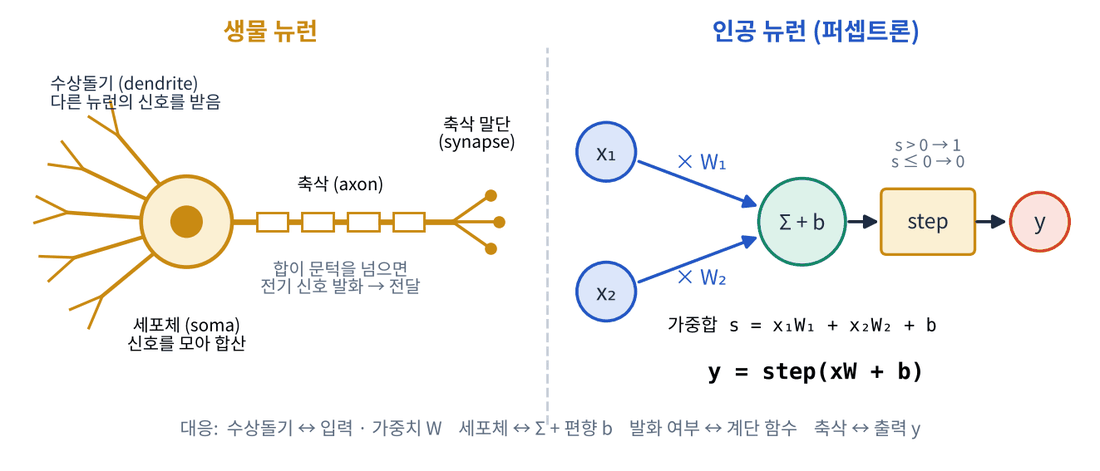

생물의 뉴런은 여러 수상돌기로 신호를 받아, 합이 어떤 문턱을 넘으면 축삭으로 신호를 내보냅니다. 1958년 Rosenblatt 의 **퍼셉트론(perceptron)** 은 이것을 식 하나로 옮겼습니다.

$$y = \begin{cases} 1 & (x_1 W_1 + x_2 W_2 + b > 0) \\ 0 & (\text{그 외}) \end{cases} \qquad\Longleftrightarrow\qquad y = \text{step}(xW + b)$$

입력을 행 벡터 $x = [x_1,\ x_2]$, 가중치를 $W = [W_1,\ W_2]^\top$ 로 놓으면 가중합은 행렬곱 $xW$ 에 편향을 더한 **$xW + b$** 입니다. 오늘 만드는 모든 모델 — 퍼셉트론, 다층 신경망, 선형 회귀, 로지스틱 회귀 — 의 가설은 이 **$XW + b$** 한 가지 모양입니다 (샘플 여러 개면 행을 쌓은 $X$).

| 기호 | 이름 | 역할 |
|---|---|---|
| $x_1, x_2$ | 입력 (input) | 센서 값, 픽셀 값 … |
| $W_1, W_2$ | 가중치 (weight) | 입력이 얼마나 **중요한지** — 클수록 출력에 큰 영향 |
| $b$ | 편향 (bias) | 뉴런이 얼마나 **쉽게 켜지는지** — 클수록 쉽게 1 |
| $s = xW + b$ | 가중합 | Day 1 의 **행렬곱** `x @ W` (= 내적) + 편향 |
| step | 계단 함수 (activation) | $s > 0$ 이면 1, 아니면 0 |

가중합 $xW + b$ 는 Day 1 5교시의 `X @ W + b` 에 샘플 하나(행 하나)만 넣은 것입니다.

**문제 1-1** 입력 `x`, 가중치 `W`, 편향 `b` 를 받아 0 또는 1 을 내는 퍼셉트론을 완성하세요.

In [ ]:
def perceptron(x, W, b):
    s = ____                 # 가중합 xW + b (행렬곱 + 편향)
    return ____      # 계단 함수

def AND(x):
    return perceptron(x, np.array([0.5, 0.5]), -0.7)

In [ ]:
print(" x1 x2 | AND")
for x in X4:
    print(f"  {x[0]}  {x[1]} |  {AND(x)}")
assert [AND(x) for x in X4] == [0, 0, 0, 1]; print("✅")

In [ ]:
#@title 🔒 정답 보기 1-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAxLTEg4pSA4pSACmRlZiBwZXJjZXB0cm9uKHgsIFcsIGIpOgogICAgcyA9IHggQCBXICsg"
    "YiAgICAgICAgICAgICAgICAgIyDqsIDspJHtlakgeFcgKyBiICjtlonroKzqs7EgKyDtjrjtlqUpCiAgICByZXR1"
    "cm4gMSBpZiBzID4gMCBlbHNlIDAgICAgICAjIOqzhOuLqCDtlajsiJgKCmRlZiBBTkQoeCk6CiAgICByZXR1cm4g"
    "cGVyY2VwdHJvbih4LCBucC5hcnJheShbMC41LCAwLjVdKSwgLTAuNyk="
).decode("utf-8"))

**문제 1-2** 같은 퍼셉트론으로 가중치와 편향만 바꿔 **NAND** 와 **OR** 게이트를 만드세요. (NAND = AND 의 반대)

| x1 | x2 | AND | NAND | OR |
|---|---|---|---|---|
| 0 | 0 | 0 | 1 | 0 |
| 0 | 1 | 0 | 1 | 1 |
| 1 | 0 | 0 | 1 | 1 |
| 1 | 1 | 1 | 0 | 1 |

In [ ]:
def NAND(x):
    return perceptron(x, np.array([____]), ____)

def OR(x):
    return perceptron(x, np.array([0.5, 0.5]), ____)

In [ ]:
assert [NAND(x) for x in X4] == [1, 1, 1, 0]
assert [OR(x) for x in X4] == [0, 1, 1, 1]
print("✅ NAND:", [NAND(x) for x in X4], " OR:", [OR(x) for x in X4])

In [ ]:
#@title 🔒 정답 보기 1-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAxLTIg4pSA4pSACmRlZiBOQU5EKHgpOgogICAgcmV0dXJuIHBlcmNlcHRyb24oeCwgbnAu"
    "YXJyYXkoWy0wLjUsIC0wLjVdKSwgMC43KQoKZGVmIE9SKHgpOgogICAgcmV0dXJuIHBlcmNlcHRyb24oeCwgbnAu"
    "YXJyYXkoWzAuNSwgMC41XSksIC0wLjIpCgrwn5KhIO2VtOyEpArqsIDspJHsuZgg64u17J2AIO2VmOuCmOqwgCDs"
    "lYTri5nri4jri6QuIOynhOumrO2RnOunjCDrp57snLzrqbQg65Cp64uI64ukLiBOQU5EIOuKlCBBTkQg7J2YIOqw"
    "gOykkey5mMK37Y647ZalIOu2gO2YuOulvCDrqqjrkZAg65Kk7KeR7J2AIOqygyhXPSgtMC41LC0wLjUpLCBiPTAu"
    "NynsnbTqs6AsIE9SIOydgCBBTkQg67O064ukIO2OuO2WpeydhCDtgqTsm4woLTAuNyDihpIgLTAuMikg7J6F66Cl"
    "IO2VmOuCmOunjCAxIOydtOyWtOuPhCDsvJzsp4Dqsowg7ZWcIOqyg+yeheuLiOuLpC4="
).decode("utf-8"))

### 그림으로 보는 게이트 — 퍼셉트론은 평면에 **직선**을 긋는다

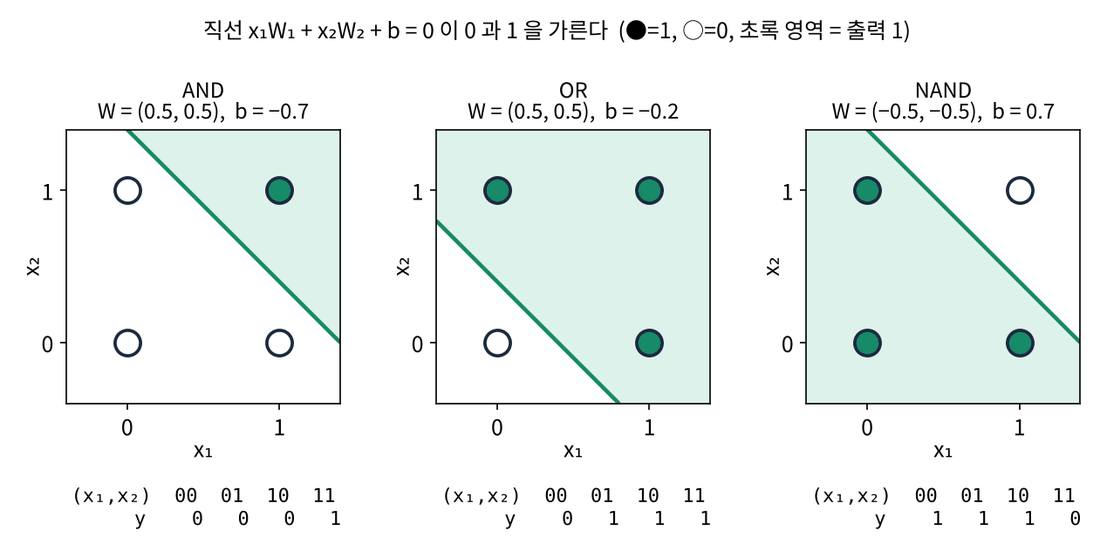

$x_1 W_1 + x_2 W_2 + b = 0$ 은 $(x_1, x_2)$ 평면 위의 **직선**입니다. 퍼셉트론은 이 직선의 한쪽(가중합 > 0)을 1, 반대쪽을 0 으로 나눕니다. 이 직선을 **결정 경계(decision boundary)** 라고 부릅니다.

- **가중치 $W$** 는 직선의 **기울기(방향)** 를, **편향 $b$** 는 직선의 **위치**를 정합니다. AND 와 OR 은 가중치가 같고 편향만 다르므로 **평행한 직선**입니다.
- 게이트 셋이 모두 **같은 함수, 다른 숫자**입니다. 기능은 코드가 아니라 **숫자(파라미터)** 에 들어 있습니다 — Day 1 에서 말한 "규칙 = 숫자의 모음"이 바로 이것입니다.

#### ⚠️ 자주 하는 실수

- `x @ W` 와 `x * W` 혼동 — `x * W` 는 원소별 곱(배열)이라 `> 0` 비교가 배열이 되어 `if` 에서 오류가 납니다. 가중합은 **행렬곱** `x @ W` 입니다.
- 계단 함수의 경계 — `s >= 0` 으로 쓰면 가중합이 정확히 0 인 입력에서 답이 달라집니다. 이 과정은 `s > 0` 을 씁니다.

#### 📌 1교시 정리

- 퍼셉트론: $y = \text{step}(xW + b)$ — 가중합(행렬곱 + 편향) + 계단 함수.
- 가중치는 방향, 편향은 위치 → 평면을 직선 하나로 나눈다.
- AND · NAND · OR 은 같은 퍼셉트론에 **숫자만 다르게** 넣은 것.

## 2교시 — 퍼셉트론 학습과 한계

1교시에서는 가중치를 **사람이 정했습니다**. 이번에는 진리표(데이터)만 주고 퍼셉트론이 가중치를 **스스로 찾게** 합니다.

> 🎬 **애니메이션** [D2-2 퍼셉트론 학습](https://imguru-mooc.github.io/AI_CAMPUS/NN-day2/animation.html#d2-2)  
> 📝 **워크시트** [2교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/NN-day2/worksheet.html#t2)  
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

### 퍼셉트론 학습 규칙

샘플 하나 $(x, t)$ 를 보고 출력 $y$ 가 틀렸을 때만 가중치를 고칩니다.

$$W \leftarrow W - \eta\,(y - t)\,x, \qquad b \leftarrow b - \eta\,(y - t)$$

| 상황 | $y - t$ (오차) | 변화 | 의미 |
|---|---|---|---|
| 맞힘 ($y = t$) | 0 | 그대로 | 맞으면 건드리지 않는다 |
| 1 이어야 하는데 0 | −1 | $W$ 에 $\eta x$ 를 **더함** | 가중합을 키워 다음엔 켜지게 |
| 0 이어야 하는데 1 | +1 | $W$ 에서 $\eta x$ 를 **뺌** | 가중합을 줄여 다음엔 꺼지게 |

$\eta$ (eta) 는 Day 1 의 **학습률** — 한 번에 얼마나 크게 고칠지입니다.

> **(오차) × (입력)** — $(y - t)\,x$ 는 오늘 계속 나오는 모양입니다. 7교시 선형 회귀와 8교시 로지스틱 회귀의 경사하강 기울기도 정확히 $(y - t)\,x$ 이고, 갱신식도 $W \leftarrow W - \eta \cdot (\text{기울기})$ 로 똑같습니다.

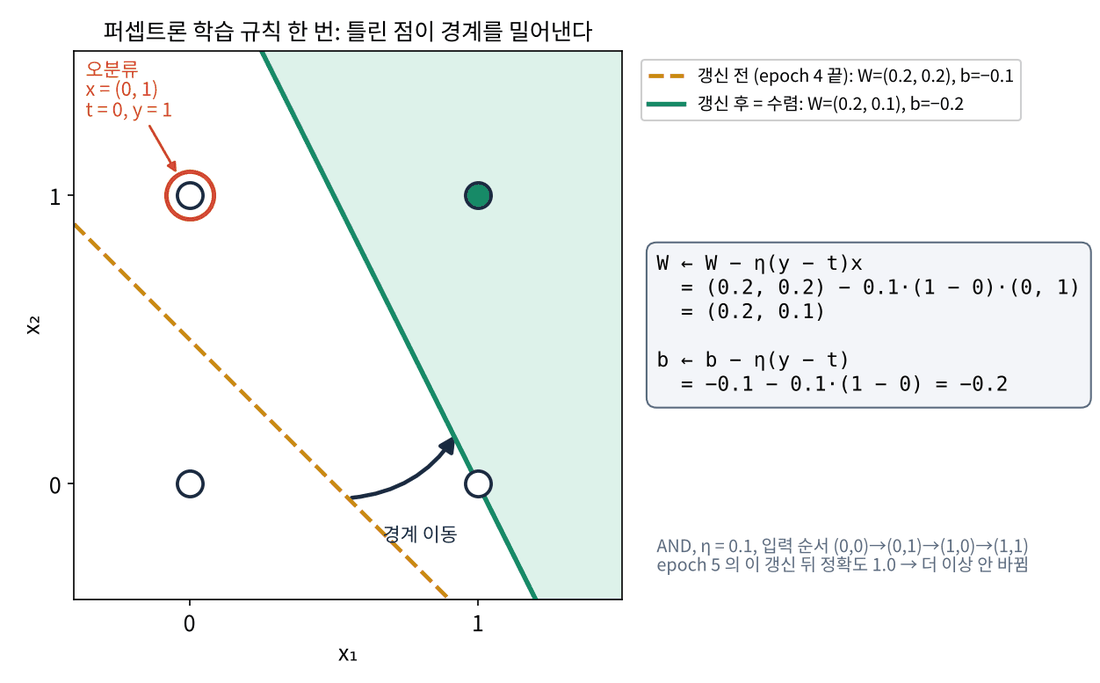

**문제 2-1** 학습 규칙을 그대로 코드로 옮기세요. 데이터 전체를 한 바퀴 도는 것을 **epoch** 라고 합니다.

In [ ]:
def train_perceptron(X, T, lr=0.1, epochs=10):
    W = np.zeros(2)
    b = 0.0
    history = []                       # epoch 마다 정확도
    for epoch in range(epochs):
        for x, t in zip(X, T):
            y = perceptron(x, W, b)
            W = W - ____     # (오차) × (입력)
            b = b - ____
        acc = np.mean([perceptron(x, W, b) == t for x, t in zip(X, T)])
        history.append(float(acc))
    return W, b, history

In [ ]:
w_and, b_and, hist_and = train_perceptron(X4, np.array([0, 0, 0, 1]))
print("epoch 별 정확도:", hist_and)
print("학습된 W =", w_and, " b =", round(b_and, 2))
assert hist_and[-1] == 1.0 and np.allclose(w_and, [0.2, 0.1]) and np.isclose(b_and, -0.2); print("✅")

In [ ]:
#@title 🔒 정답 보기 2-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTEg4pSA4pSACmRlZiB0cmFpbl9wZXJjZXB0cm9uKFgsIFQsIGxyPTAuMSwgZXBvY2hz"
    "PTEwKToKICAgIFcgPSBucC56ZXJvcygyKQogICAgYiA9IDAuMAogICAgaGlzdG9yeSA9IFtdICAgICAgICAgICAg"
    "ICAgICAgICAgICAjIGVwb2NoIOuniOuLpCDsoJXtmZXrj4QKICAgIGZvciBlcG9jaCBpbiByYW5nZShlcG9jaHMp"
    "OgogICAgICAgIGZvciB4LCB0IGluIHppcChYLCBUKToKICAgICAgICAgICAgeSA9IHBlcmNlcHRyb24oeCwgVywg"
    "YikKICAgICAgICAgICAgVyA9IFcgLSBsciAqICh5IC0gdCkgKiB4ICAgICAjICjsmKTssKgpIMOXICjsnoXroKUp"
    "CiAgICAgICAgICAgIGIgPSBiIC0gbHIgKiAoeSAtIHQpCiAgICAgICAgYWNjID0gbnAubWVhbihbcGVyY2VwdHJv"
    "bih4LCBXLCBiKSA9PSB0IGZvciB4LCB0IGluIHppcChYLCBUKV0pCiAgICAgICAgaGlzdG9yeS5hcHBlbmQoZmxv"
    "YXQoYWNjKSkKICAgIHJldHVybiBXLCBiLCBoaXN0b3J5Cgrwn5KhIO2VtOyEpAp5IC0gdCDqsIAgMCDsnbTrqbQg"
    "7JWE66y06rKD64+EIOuwlOuAjOyngCDslYrsnLzrr4DroZwgJ+2LgOuguOydhCDrlYzrp4wg6rOg7LmY64qUJyDq"
    "t5zsuZnsnbQg65Cp64uI64ukLiBBTkQg64qUIDXrsojsp7ggZXBvY2gg7JeQ7IScIDTqsJzrpbwg66qo65GQIOun"
    "nu2eiOqzoCBXPSgwLjIsIDAuMSksIGI9LTAuMiDsl5DshJwg66mI7Lal64uI64ukLiAx6rWQ7Iuc7JeQ7IScIOyC"
    "rOuejOydtCDsoJXtlZwgKDAuNSwgMC41LCAtMC43KSDqs7wg7Iir7J6Q64qUIOuLpOultOyngOunjCDqsJnsnYAg"
    "7KeE66as7ZGc66W8IOunjOuTnOuKlCDrmJAg7ZWY64KY7J2YIOuLteyeheuLiOuLpC4="
).decode("utf-8"))

**문제 2-2** 결정 경계 $x_1 W_1 + x_2 W_2 + b = 0$ 을 $x_2$ 에 대해 풀어 직선을 그리는 함수를 완성하세요.

$$x_2 = -\frac{W_1 x_1 + b}{W_2}$$

In [ ]:
def boundary_x2(x1, W, b):
    return ____

In [ ]:
assert np.isclose(boundary_x2(0, np.array([0.2, 0.1]), -0.2), 2.0)
x1s = np.linspace(-0.5, 1.5, 50)
plt.scatter(X4[:, 0], X4[:, 1], c=[0, 0, 0, 1], cmap="coolwarm", s=120, edgecolors="k")
plt.plot(x1s, boundary_x2(x1s, w_and, b_and), "g--", label="learned boundary")
plt.xlim(-0.5, 1.5); plt.ylim(-0.5, 1.5); plt.legend(); plt.title("AND - trained perceptron"); plt.grid(alpha=.3); plt.show()
print("✅")

In [ ]:
#@title 🔒 정답 보기 2-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTIg4pSA4pSACmRlZiBib3VuZGFyeV94Mih4MSwgVywgYik6CiAgICByZXR1cm4gLShX"
    "WzBdICogeDEgKyBiKSAvIFdbMV0="
).decode("utf-8"))

### 같은 방법으로 XOR 을 학습하면?

XOR 은 두 입력이 **서로 다를 때만** 1 입니다 — (0,1), (1,0) → 1, (0,0), (1,1) → 0. 50 epoch 을 돌려 봅니다.

In [ ]:
w_xor, b_xor, hist_xor = train_perceptron(X4, np.array([0, 1, 1, 0]), epochs=50)
print("마지막 10 epoch 정확도:", hist_xor[-10:])
print("50 epoch 중 최고 정확도:", max(hist_xor))
plt.plot(hist_and + [1.0] * 40, label="AND"); plt.plot(hist_xor, label="XOR")
plt.ylim(0, 1.05); plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend(); plt.grid(alpha=.3); plt.show()

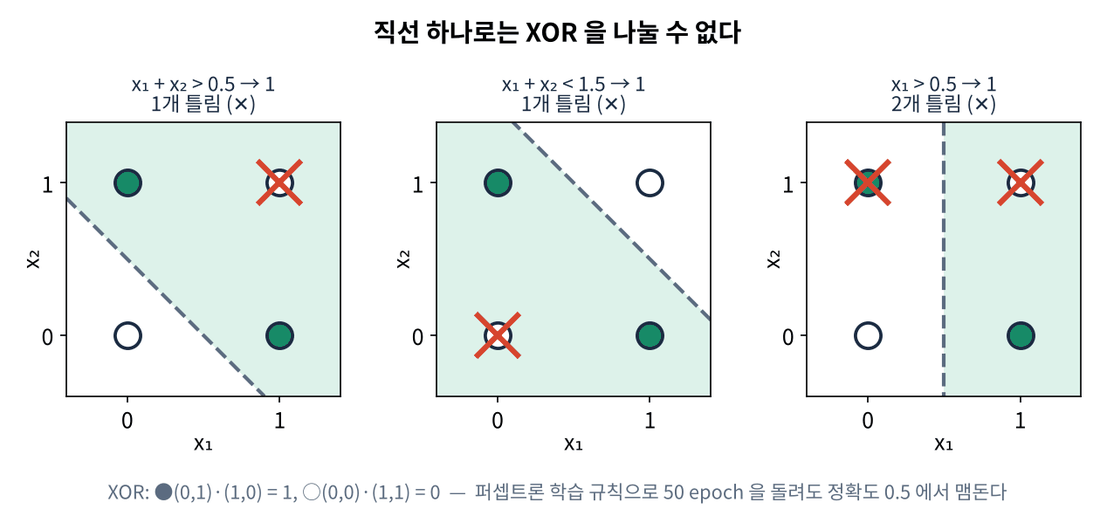

아무리 학습해도 정확도가 1.0 이 되지 않습니다. **학습 방법이 나빠서가 아니라 모델이 표현할 수 없기 때문**입니다. XOR 의 1 두 점은 대각선으로 마주 보고 있어서, 어떤 직선을 그어도 한쪽에 1 과 0 이 섞입니다. 직선 하나로 나눌 수 있는 데이터를 **선형 분리 가능(linearly separable)** 하다고 하는데, XOR 은 그렇지 않습니다.

1969년 Minsky 와 Papert 가 이 한계를 수학적으로 보인 뒤 신경망 연구는 한동안 침체기("AI 의 첫 겨울")를 맞았습니다. 해법은 3교시의 **층 쌓기**입니다.

#### ⚠️ 자주 하는 실수

- `W = W - ...` 대신 `W -= ...` 를 쓰면 `W = np.zeros(2)` 의 dtype 이 float 이라 괜찮지만, `np.array([0, 0])` (정수)로 시작하면 `-=` 에서 **오류**(float 결과를 int 배열에 넣을 수 없음)가 납니다. 신경망 파라미터는 항상 float 로 시작하세요.
- `boundary_x2` 는 $W_2 = 0$ 이면 0 으로 나누게 됩니다 — 그때 경계는 세로선 $x_1 = -b / W_1$ 입니다.

#### 📌 2교시 정리

- 학습 규칙 $W \leftarrow W - \eta(y - t)x$: 틀렸을 때만, 틀린 쪽으로 고친다. (오차) × (입력).
- 결정 경계 $x_2 = -(W_1 x_1 + b)/W_2$ — 퍼셉트론 하나 = 직선 하나.
- XOR 은 선형 분리 불가능 → 퍼셉트론 하나로는 절대 못 푼다.

## 3교시 — 다층 퍼셉트론: XOR 풀기

직선 하나로 안 되면 **직선 두 개를 먼저 긋고, 그 결과를 다시 조합**하면 됩니다. 1교시의 게이트 셋을 쌓아 봅니다.

> 🎬 **애니메이션** [D2-3 XOR 다층 퍼셉트론](https://imguru-mooc.github.io/AI_CAMPUS/NN-day2/animation.html#d2-3)  
> 📝 **워크시트** [3교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/NN-day2/worksheet.html#t3)  
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

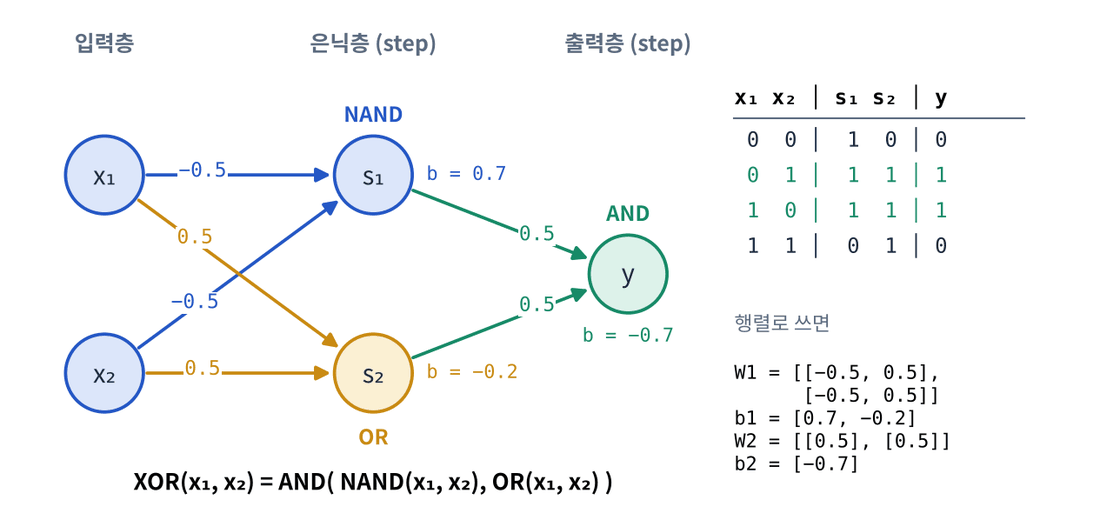

| x1 | x2 | s1 = NAND | s2 = OR | y = AND(s1, s2) |
|---|---|---|---|---|
| 0 | 0 | 1 | 0 | 0 |
| 0 | 1 | 1 | 1 | 1 |
| 1 | 0 | 1 | 1 | 1 |
| 1 | 1 | 0 | 1 | 0 |

입력과 출력 사이에 있는 $s_1, s_2$ 를 **은닉층(hidden layer)** 이라고 부릅니다. 바깥에서 직접 보이지 않는 중간 결과라는 뜻입니다.

**문제 3-1** 1교시에서 만든 게이트로 XOR 을 완성하세요.

In [ ]:
def XOR(x):
    s1 = ____
    s2 = ____
    return ____

In [ ]:
assert [XOR(x) for x in X4] == [0, 1, 1, 0]; print("✅ XOR:", [XOR(x) for x in X4])

In [ ]:
#@title 🔒 정답 보기 3-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTEg4pSA4pSACmRlZiBYT1IoeCk6CiAgICBzMSA9IE5BTkQoeCkKICAgIHMyID0gT1Io"
    "eCkKICAgIHJldHVybiBBTkQobnAuYXJyYXkoW3MxLCBzMl0pKQ=="
).decode("utf-8"))

### 은닉층은 공간을 바꾼다

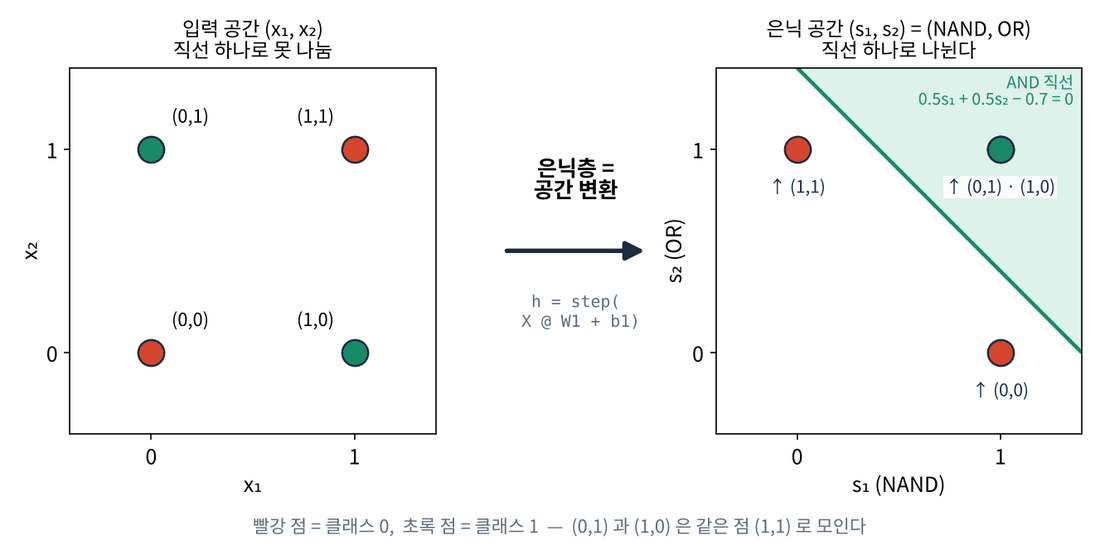

은닉층은 입력 $(x_1, x_2)$ 를 새 좌표 $(s_1, s_2)$ 로 옮깁니다. 원래 공간에서는 대각선으로 엇갈려 있던 점들이, 새 공간에서는 (0,1) 과 (1,1) 이 겹치면서 **직선 하나로 나뉘는** 배치가 됩니다. 출력층의 AND 는 그 새 공간에서 직선을 긋기만 하면 됩니다.

> **신경망의 핵심 아이디어** — 앞쪽 층들이 데이터를 "풀기 쉬운 공간"으로 옮기고, 마지막 층이 그 공간에서 간단한 경계를 긋는다. Day 5 의 CNN 도, 온디바이스 YOLO 도 이 구조입니다.

In [ ]:
for x in X4:
    print(f"x = {x}  →  (s1, s2) = ({NAND(x)}, {OR(x)})  →  XOR = {XOR(x)}")

**문제 3-2** 같은 2층 망을 **행렬**로 써서 입력 4개를 한 번에 계산하세요. 은닉층 두 뉴런의 가중치를 `W1` 의 **열**로 나란히 놓습니다 (열 0 = NAND, 열 1 = OR).

$$H = \text{step}(X W_1 + b_1), \qquad Y = \text{step}(H W_2 + b_2)$$

In [ ]:
def step_function(a):
    return (a > 0).astype(int)      # 배열 전체에 계단 함수

W1 = np.array([[-0.5, 0.5],
               [-0.5, 0.5]])       # (2, 2): 열 0 = NAND, 열 1 = OR
b1 = np.array([0.7, -0.2])
W2 = np.array([[0.5],
               [0.5]])             # (2, 1): AND
b2 = np.array([-0.7])

H = step_function(____)    # 은닉층 (4, 2)
Y = step_function(____)     # 출력층 (4, 1)

In [ ]:
assert H.tolist() == [[1, 0], [1, 1], [1, 1], [0, 1]] and Y.ravel().tolist() == [0, 1, 1, 0]
print("H =\n", H, "\nY =", Y.ravel(), " ✅")

In [ ]:
#@title 🔒 정답 보기 3-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTIg4pSA4pSACmRlZiBzdGVwX2Z1bmN0aW9uKGEpOgogICAgcmV0dXJuIChhID4gMCku"
    "YXN0eXBlKGludCkgICAgICAjIOuwsOyXtCDsoITssrTsl5Ag6rOE64uoIO2VqOyImAoKVzEgPSBucC5hcnJheShb"
    "Wy0wLjUsIDAuNV0sCiAgICAgICAgICAgICAgIFstMC41LCAwLjVdXSkgICAgICAgIyAoMiwgMik6IOyXtCAwID0g"
    "TkFORCwg7Je0IDEgPSBPUgpiMSA9IG5wLmFycmF5KFswLjcsIC0wLjJdKQpXMiA9IG5wLmFycmF5KFtbMC41XSwK"
    "ICAgICAgICAgICAgICAgWzAuNV1dKSAgICAgICAgICAgICAjICgyLCAxKTogQU5ECmIyID0gbnAuYXJyYXkoWy0w"
    "LjddKQoKSCA9IHN0ZXBfZnVuY3Rpb24oWDQgQCBXMSArIGIxKSAgICAjIOydgOuLiey4tSAoNCwgMikKWSA9IHN0"
    "ZXBfZnVuY3Rpb24oSCBAIFcyICsgYjIpICAgICAjIOy2nOugpey4tSAoNCwgMSkKCvCfkqEg7ZW07ISkClg0ICg0"
    "LCAyKSBAIFcxICgyLCAyKSArIGIxICgyLCkg4oaSICg0LCAyKTog7J6F66ClIDTqsJwgw5cg7J2A64uJIOuJtOuf"
    "sCAy6rCcLiDruIzroZzrk5zsupDsiqTtjIXsnLzroZwgYjEg7J20IOuqqOuToCDtlonsl5Ag642U7ZW07KeR64uI"
    "64ukKERheSAxIDPqtZDsi5wpLiDribTrn7Ag7ZWY64KY7ZWY64KY66W8IGZvciDrrLjsnLzroZwg67aA66W0642Y"
    "IDMtMSDsnbQg7ZaJ66Cs6rOxIO2VnCDrsojsnbQg65CY7JeI7Iq164uI64ukIOKAlCDsnbTqsoPsnbQgNeq1kOyL"
    "nCAn7ZaJ66Cs66GcIOuztOuKlCDsiJzsoITtjIwn7J2YIOy2nOuwnOygkOyeheuLiOuLpC4="
).decode("utf-8"))

### 그런데 — 가중치는 누가 정했나?

지금까지 XOR 망의 가중치는 **사람이 진리표를 보고 정했습니다**. 수천 개 뉴런이 있는 망은 그렇게 할 수 없으니, Day 1 의 **경사하강**으로 찾아야 합니다. 그런데 경사하강은 **기울기(미분)** 가 필요하고, 계단 함수는 거의 모든 곳에서 기울기가 **0** 입니다 — 가중치를 조금 바꿔도 출력이 0 → 0 그대로라서 "어느 쪽으로 고쳐야 하는지" 알려 주지 못합니다.

그래서 4교시에서 계단 함수를 **매끄러운 활성화 함수**로 바꿉니다.

#### 📌 3교시 정리

- 층을 쌓으면(다층 퍼셉트론, MLP) 직선 하나로 못 푸는 문제도 풀 수 있다.
- 은닉층 = 공간 변환. 마지막 층은 바뀐 공간에서 간단한 경계를 긋는다.
- 층 하나 = `step(X @ W + b)` — 뉴런 여러 개를 행렬 한 번으로.
- 가중치를 **학습**하려면 미분 가능한 활성화 함수가 필요하다 → 4교시.

## 4교시 — 활성화 함수

**활성화 함수(activation function)** 는 가중합 $a = xW + b$ 를 받아 뉴런의 출력을 정하는 함수입니다. 계단 함수 대신 **매끄럽게 변하는** 함수를 쓰면 기울기가 생겨 경사하강으로 학습할 수 있습니다.

> 🎬 **애니메이션** [D2-4 활성화 함수](https://imguru-mooc.github.io/AI_CAMPUS/NN-day2/animation.html#d2-4)  
> 📝 **워크시트** [4교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/NN-day2/worksheet.html#t4)  
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

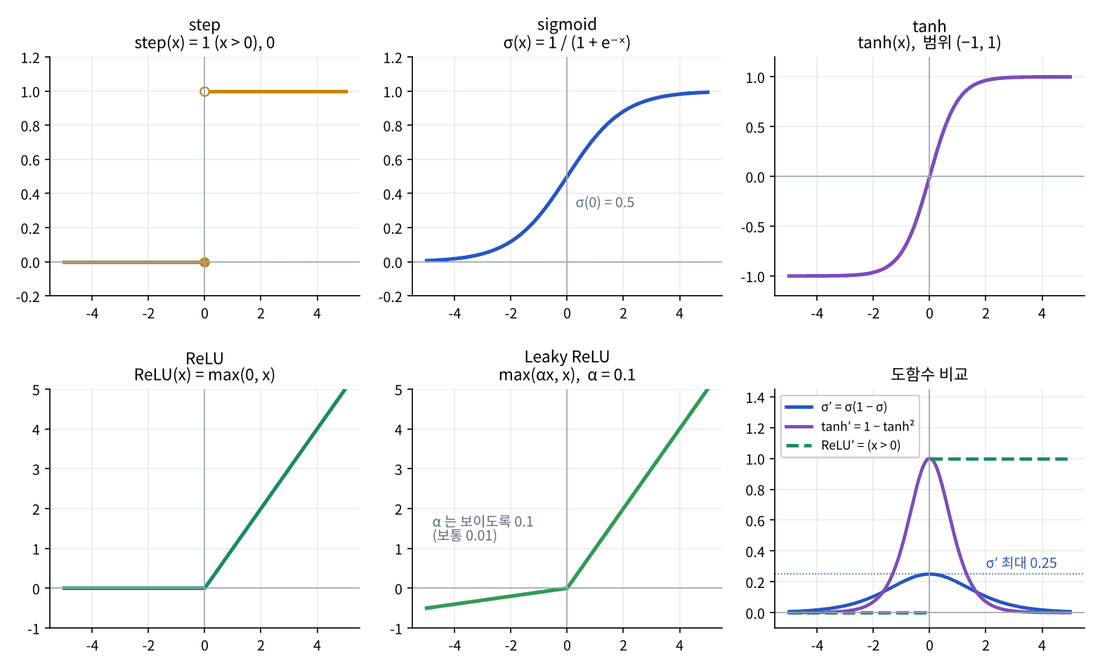

| 함수 | 식 | 출력 범위 | 도함수 | 주로 쓰는 곳 |
|---|---|---|---|---|
| step | $1\ (a > 0)$, $0$ | {0, 1} | 0 (거의 모든 곳) | 퍼셉트론 (학습 불가) |
| sigmoid | $\frac{1}{1 + e^{-a}}$ | (0, 1) | $\sigma(a)(1 - \sigma(a))$, 최대 0.25 | 이진 분류 출력 (8교시) |
| tanh | $\frac{e^a - e^{-a}}{e^a + e^{-a}}$ | (−1, 1) | $1 - \tanh^2 a$, 최대 1 | RNN, 0 중심이 필요할 때 |
| ReLU | $\max(0, a)$ | [0, ∞) | 1 ($a > 0$), 0 | **은닉층의 기본값** |
| Leaky ReLU | $a\ (a > 0)$, $\alpha a$ | (−∞, ∞) | 1, $\alpha$ | ReLU 가 0 에 갇힐 때 |

sigmoid 는 "부드러운 계단 함수"입니다. 큰 음수 → 0 근처, 큰 양수 → 1 근처, 0 → 0.5. 출력을 **확률**처럼 읽을 수 있어 8교시 분류기에 씁니다.

**문제 4-1** sigmoid 를 NumPy 로 구현하세요. 배열을 넣으면 원소마다 계산되어야 합니다(벡터화).

In [ ]:
def sigmoid(a):
    return ____

In [ ]:
assert sigmoid(0) == 0.5
assert np.allclose(sigmoid(np.array([-1.0, 1.0])).sum(), 1.0)      # σ(-a) = 1 - σ(a)
assert sigmoid(np.array([-10.0, 0.0, 10.0])).shape == (3,)
print("✅", sigmoid(np.array([-10.0, -1.0, 0.0, 1.0, 10.0])))

In [ ]:
#@title 🔒 정답 보기 4-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTEg4pSA4pSACmRlZiBzaWdtb2lkKGEpOgogICAgcmV0dXJuIDEgLyAoMSArIG5wLmV4"
    "cCgtYSkp"
).decode("utf-8"))

**문제 4-2** ReLU 와 Leaky ReLU 를 구현하세요. `np.maximum` 은 원소별 최댓값, `np.where(조건, A, B)` 는 조건이 참인 자리는 A, 거짓인 자리는 B 입니다.

In [ ]:
def relu(a):
    return ____

def leaky_relu(a, alpha=0.01):
    return ____

In [ ]:
a = np.array([-2.0, -0.5, 0.0, 0.5, 2.0])
assert np.allclose(relu(a), [0, 0, 0, 0.5, 2])
assert np.allclose(leaky_relu(a), [-0.02, -0.005, 0, 0.5, 2])
print("✅ relu:", relu(a), " leaky:", leaky_relu(a))

xs = np.linspace(-4, 4, 200)
fig, ax = plt.subplots(1, 4, figsize=(15, 3))
for axi, (f, name) in zip(ax, [(step_function, "step"), (sigmoid, "sigmoid"), (np.tanh, "tanh"), (relu, "ReLU")]):
    axi.plot(xs, f(xs)); axi.set_title(name); axi.grid(alpha=.3); axi.axhline(0, color="k", lw=.5); axi.axvline(0, color="k", lw=.5)
plt.show()

In [ ]:
#@title 🔒 정답 보기 4-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTIg4pSA4pSACmRlZiByZWx1KGEpOgogICAgcmV0dXJuIG5wLm1heGltdW0oMCwgYSkK"
    "CmRlZiBsZWFreV9yZWx1KGEsIGFscGhhPTAuMDEpOgogICAgcmV0dXJuIG5wLndoZXJlKGEgPiAwLCBhLCBhbHBo"
    "YSAqIGEp"
).decode("utf-8"))

**문제 4-3** 도함수를 구현하고 Day 1 의 중앙 차분과 비교해 확인하세요.

$$\sigma'(a) = \sigma(a)\,(1 - \sigma(a)), \qquad \text{ReLU}'(a) = \begin{cases} 1 & a > 0 \\ 0 & a \le 0 \end{cases}$$

In [ ]:
def sigmoid_grad(a):
    s = sigmoid(a)
    return ____

def relu_grad(a):
    return ____

In [ ]:
pts = np.array([-3.0, -0.7, 0.0, 1.2, 4.0])
h = 1e-4
num = (sigmoid(pts + h) - sigmoid(pts - h)) / (2 * h)        # Day 1 중앙 차분
assert np.allclose(sigmoid_grad(pts), num, atol=1e-8)
assert sigmoid_grad(0) == 0.25 and relu_grad(np.array([-1.0, 2.0])).tolist() == [0.0, 1.0]
print("✅ 해석 미분 =", sigmoid_grad(pts), "\n   수치 미분 =", num)

In [ ]:
#@title 🔒 정답 보기 4-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTMg4pSA4pSACmRlZiBzaWdtb2lkX2dyYWQoYSk6CiAgICBzID0gc2lnbW9pZChhKQog"
    "ICAgcmV0dXJuIHMgKiAoMSAtIHMpCgpkZWYgcmVsdV9ncmFkKGEpOgogICAgcmV0dXJuIChhID4gMCkuYXN0eXBl"
    "KGZsb2F0KQoK8J+SoSDtlbTshKQKcyAqICgxIC0gcykg64qUIHNpZ21vaWQg6rCS66eM7Jy866GcIOq4sOyauOq4"
    "sOulvCDqs4TsgrDtlZjripQg6rO17Iud7J6F64uI64ukLiBEYXkgMyDsl63soITtjIzsl5DshJwg7Iic7KCE7YyM"
    "IOuVjCDsoIDsnqXtlbQg65GUIOy2nOugpSBzIOulvCDqt7jrjIDroZwg7J6s7IKs7Jqp7ZWY66+A66GcIGV4cCDr"
    "pbwg64uk7IucIOqzhOyCsO2VoCDtlYTsmpTqsIAg7JeG7Iq164uI64ukLg=="
).decode("utf-8"))

### 왜 비선형이어야 하나 — 선형 층은 아무리 쌓아도 한 층

활성화 함수 없이 층 두 개를 쌓으면

$$(X W_a) W_b = X (W_a W_b) = X W$$

즉 **층 하나와 똑같습니다**. 층을 100개 쌓아도 결정 경계는 여전히 직선 하나라서 XOR 을 풀 수 없습니다. 층 사이에 **비선형** 활성화 함수가 끼어야 층을 쌓는 의미가 생깁니다.

**문제 4-4** 선형 층 두 개를 합친 가중치 `W` 를 구해, 두 층을 통과한 결과와 한 층을 통과한 결과가 같은지 확인하세요.

In [ ]:
rng4 = np.random.default_rng(4)
Wa = rng4.normal(size=(2, 3))           # 층 1: 2 → 3
Wb = rng4.normal(size=(3, 2))           # 층 2: 3 → 2
Xs = rng4.normal(size=(5, 2))

two_layers = (Xs @ Wa) @ Wb
W = ____                            # 하나로 합친 가중치
one_layer = Xs @ W

In [ ]:
assert W.shape == (2, 2) and np.allclose(two_layers, one_layer)
with_relu = relu(Xs @ Wa) @ Wb
print("✅ 선형 2층 = 선형 1층:", np.allclose(two_layers, one_layer), " | ReLU 를 넣으면 같은가?", np.allclose(with_relu, one_layer))

In [ ]:
#@title 🔒 정답 보기 4-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTQg4pSA4pSACnJuZzQgPSBucC5yYW5kb20uZGVmYXVsdF9ybmcoNCkKV2EgPSBybmc0"
    "Lm5vcm1hbChzaXplPSgyLCAzKSkgICAgICAgICAgICMg7Li1IDE6IDIg4oaSIDMKV2IgPSBybmc0Lm5vcm1hbChz"
    "aXplPSgzLCAyKSkgICAgICAgICAgICMg7Li1IDI6IDMg4oaSIDIKWHMgPSBybmc0Lm5vcm1hbChzaXplPSg1LCAy"
    "KSkKCnR3b19sYXllcnMgPSAoWHMgQCBXYSkgQCBXYgpXID0gV2EgQCBXYiAgICAgICAgICAgICAgICAgICAgICAg"
    "ICAgICAjIO2VmOuCmOuhnCDtlansuZwg6rCA7KSR7LmYCm9uZV9sYXllciA9IFhzIEAgVw=="
).decode("utf-8"))

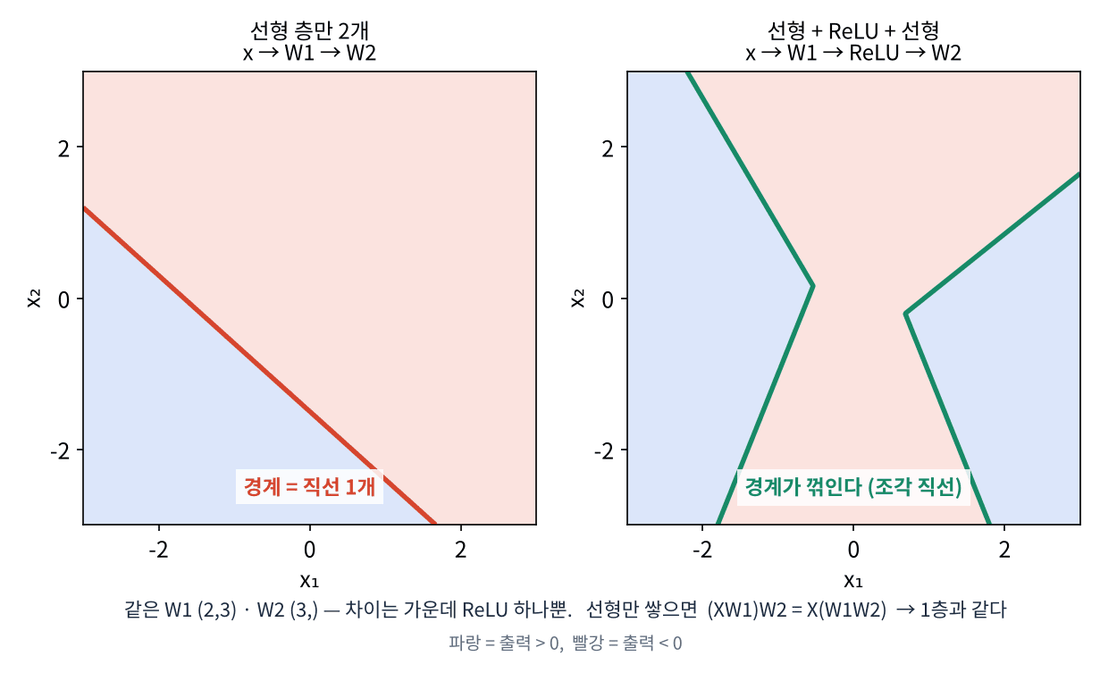

### 기울기 소실 — sigmoid 를 깊게 쌓을 때의 문제

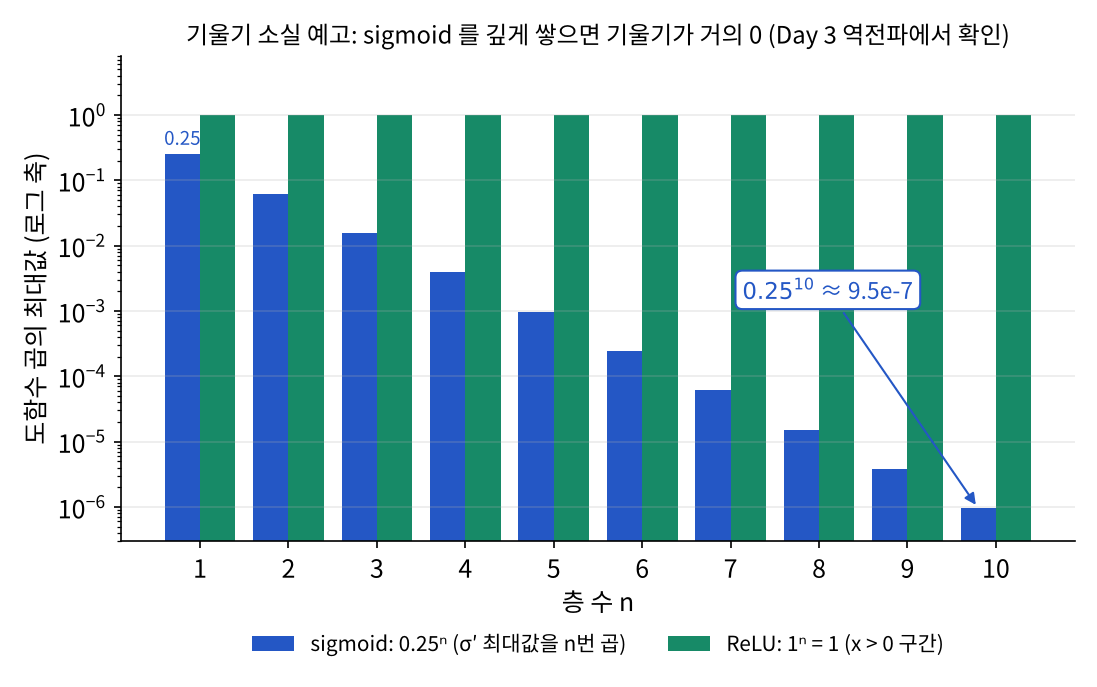

sigmoid 의 기울기는 **최대 0.25** 입니다. Day 3 역전파에서는 층마다 기울기를 **곱해** 앞으로 전달하는데, sigmoid 층 10개를 지나면 많아야 $0.25^{10} \approx 9.5 \times 10^{-7}$ — 앞쪽 층에는 기울기가 거의 도착하지 않아 학습이 멈춥니다. 이것을 **기울기 소실(vanishing gradient)** 이라고 하며, 양수 구간 기울기가 1 인 **ReLU** 가 은닉층의 기본값이 된 이유입니다.

In [ ]:
for n in [1, 2, 5, 10, 20]:
    print(f"sigmoid 층 {n:2d}개: 기울기 곱 ≤ {0.25 ** n:.2e}   |  ReLU (양수 구간): {1.0 ** n}")

#### ⚠️ 자주 하는 실수

- `np.max(0, a)` — `np.max` 는 배열 하나의 최댓값(축 지정)입니다. 원소별 비교는 `np.maximum(0, a)`.
- `sigmoid(-1000)` 은 `np.exp(1000)` = inf 경고가 나지만 결과 0.0 은 맞습니다. 경고가 거슬리면 `np.clip(a, -500, 500)`.
- 정수 배열을 넣으면 `relu_grad` 등은 괜찮지만, 결과를 다시 정수 배열에 넣으면 잘립니다 — 신경망 배열은 항상 float.

#### 📌 4교시 정리

- 활성화 함수 = 가중합을 출력으로 바꾸는 **비선형** 함수. 계단 → sigmoid 로 바꾸면 미분 가능 → 학습 가능.
- 비선형이 없으면 층을 쌓아도 한 층 ($W_a W_b = W$).
- sigmoid' 최대 0.25 → 깊으면 기울기 소실 → 은닉층은 ReLU, 출력층은 목적에 맞게(6교시).

## 5교시 — 행렬로 보는 순전파

이제 뉴런을 여러 층으로 쌓은 신경망에 입력을 넣어 출력을 계산합니다. 입력 → 출력 방향으로 계산이 흐르므로 **순전파(forward propagation)** 라고 합니다. 학습이 끝난 모델을 기기에서 실행하는 **추론(inference)** 이 바로 이 순전파입니다 — 온디바이스 AI 의 Jetson 이 하는 일입니다.

> 🎬 **애니메이션** [D2-5 순전파 흐름](https://imguru-mooc.github.io/AI_CAMPUS/NN-day2/animation.html#d2-5)  
> 📝 **워크시트** [5교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/NN-day2/worksheet.html#t5)  
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

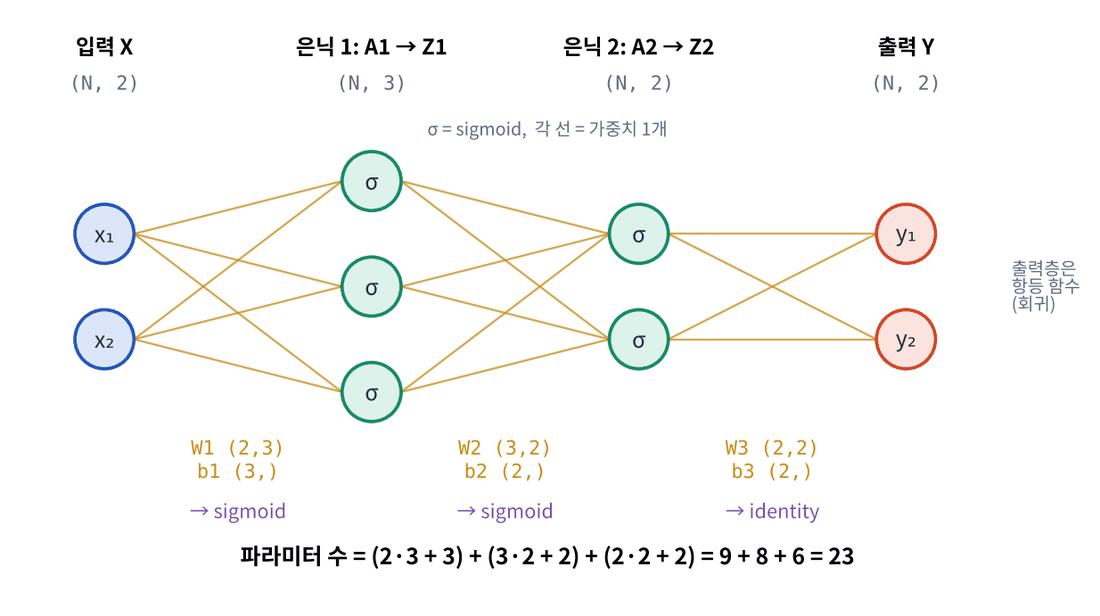

이번 예제 망은 입력 2 → 은닉 3 → 은닉 2 → 출력 2 입니다. 층마다 같은 두 단계를 반복합니다.

1. **가중합** $A = X W + b$ — Day 1 의 행렬곱 + 브로드캐스팅
2. **활성화** $Z = h(A)$ — 은닉층은 sigmoid, 출력층은 항등 함수(identity)

| 기호 | 뜻 | shape (배치 N) |
|---|---|---|
| `X` | 입력 | (N, 2) |
| `W1, b1` | 층 1 가중치 · 편향 | (2, 3), (3,) |
| `A1 → Z1` | 층 1 가중합 → sigmoid | (N, 3) |
| `W2, b2` | 층 2 | (3, 2), (2,) |
| `A2 → Z2` | 층 2 가중합 → sigmoid | (N, 2) |
| `W3, b3` | 출력층 | (2, 2), (2,) |
| `A3 → Y` | 출력 (identity) | (N, 2) |

규칙은 Day 1 그대로입니다 — `W` 의 **행 수 = 이전 층 뉴런 수**, **열 수 = 이번 층 뉴런 수**, 편향 길이 = 이번 층 뉴런 수.

In [ ]:
def init_network():
    network = {}
    network["W1"] = np.array([[0.1, 0.3, 0.5], [0.2, 0.4, 0.6]])
    network["b1"] = np.array([0.1, 0.2, 0.3])
    network["W2"] = np.array([[0.1, 0.4], [0.2, 0.5], [0.3, 0.6]])
    network["b2"] = np.array([0.1, 0.2])
    network["W3"] = np.array([[0.1, 0.3], [0.2, 0.4]])
    network["b3"] = np.array([0.1, 0.2])
    return network

network = init_network()

**문제 5-1** 코드를 실행하기 전에, 각 파라미터의 shape 를 예측해 튜플로 쓰세요.

In [ ]:
shapes = {
    "W1": ____, "b1": ____,
    "W2": ____, "b2": ____,
    "W3": ____, "b3": ____,
}

In [ ]:
for k, v in shapes.items():
    print(f"{'✅' if network[k].shape == v else '❌'} {k}: 실제 {network[k].shape}  내 답 {v}")
assert all(network[k].shape == v for k, v in shapes.items())

In [ ]:
#@title 🔒 정답 보기 5-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTEg4pSA4pSACnNoYXBlcyA9IHsKICAgICJXMSI6ICgyLCAzKSwgImIxIjogKDMsKSwK"
    "ICAgICJXMiI6ICgzLCAyKSwgImIyIjogKDIsKSwKICAgICJXMyI6ICgyLCAyKSwgImIzIjogKDIsKSwKfQ=="
).decode("utf-8"))

**문제 5-2** 순전파 함수를 완성하세요. 은닉층 두 개는 sigmoid, 출력층은 항등 함수입니다.

In [ ]:
def identity(a):
    return a

def forward(network, X):
    W1, W2, W3 = network["W1"], network["W2"], network["W3"]
    b1, b2, b3 = network["b1"], network["b2"], network["b3"]
    A1 = ____
    Z1 = ____
    A2 = ____
    Z2 = sigmoid(A2)
    A3 = ____
    return identity(A3)

In [ ]:
Y1 = forward(network, np.array([[1.0, 0.5]]))
print("Y =", Y1)
assert np.allclose(Y1, [[0.31682708, 0.69627909]])

Xb = np.array([[1.0, 0.5], [0.0, 0.0], [-1.0, 2.0], [3.0, -1.0]])     # 배치 4개
Yb = forward(network, Xb)
assert Yb.shape == (4, 2) and np.allclose(Yb[0], Y1[0])               # 배치로 해도 한 개씩 한 것과 같다
print("✅ 배치 출력 shape:", Yb.shape)

In [ ]:
#@title 🔒 정답 보기 5-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTIg4pSA4pSACmRlZiBpZGVudGl0eShhKToKICAgIHJldHVybiBhCgpkZWYgZm9yd2Fy"
    "ZChuZXR3b3JrLCBYKToKICAgIFcxLCBXMiwgVzMgPSBuZXR3b3JrWyJXMSJdLCBuZXR3b3JrWyJXMiJdLCBuZXR3"
    "b3JrWyJXMyJdCiAgICBiMSwgYjIsIGIzID0gbmV0d29ya1siYjEiXSwgbmV0d29ya1siYjIiXSwgbmV0d29ya1si"
    "YjMiXQogICAgQTEgPSBYIEAgVzEgKyBiMQogICAgWjEgPSBzaWdtb2lkKEExKQogICAgQTIgPSBaMSBAIFcyICsg"
    "YjIKICAgIFoyID0gc2lnbW9pZChBMikKICAgIEEzID0gWjIgQCBXMyArIGIzCiAgICByZXR1cm4gaWRlbnRpdHko"
    "QTMpCgrwn5KhIO2VtOyEpArsuLXrp4jri6QgJ+qwgOykke2VqSDihpIg7Zmc7ISx7ZmUJ+ulvCDrsJjrs7XtlaAg"
    "67+Q7J6F64uI64ukLiBYIOqwgCAoMSwgMikg7J2065OgICg0LCAyKSDsnbTrk6Ag7L2U65Oc64qUIOqwmeyKteuL"
    "iOuLpCDigJQg7ZaJIO2VmOuCmOqwgCDsg5jtlIwg7ZWY64KY7J206rOgLCDtlonroKzqs7HsnbQg7IOY7ZSM65Ok"
    "7J2EIO2VnOq6vOuyiOyXkCDsspjrpqztlanri4jri6Qo67Cw7LmYIOyymOumrCkuIEdQVSDCtyBOUFUg6rCAIOu5"
    "oOuluCDsnbTsnKDrj4Qg7J20IO2BsCDtlonroKzqs7HsnYQg67OR66Cs66GcIO2VmOq4sCDrlYzrrLjsnoXri4jr"
    "i6Qu"
).decode("utf-8"))

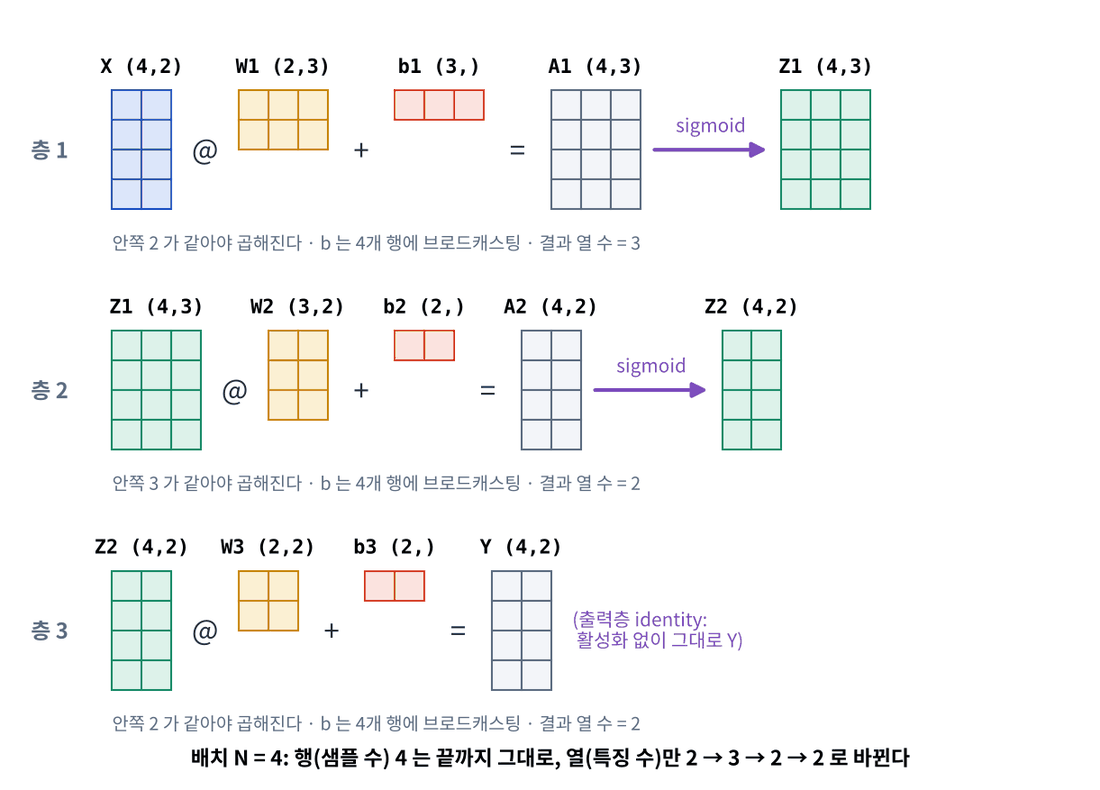

아래 셀은 층마다 shape 를 출력합니다. 오류가 나면 **가장 먼저 shape 를 찍어 보는** 습관이 Day 3 이후에도 가장 큰 도움이 됩니다.

In [ ]:
A1 = Xb @ network["W1"] + network["b1"];  Z1 = sigmoid(A1)
A2 = Z1 @ network["W2"] + network["b2"];  Z2 = sigmoid(A2)
A3 = Z2 @ network["W3"] + network["b3"]
for name, arr in [("X", Xb), ("A1", A1), ("Z1", Z1), ("A2", A2), ("Z2", Z2), ("Y = A3", A3)]:
    print(f"{name:7s} {arr.shape}")

**문제 5-3** 신경망의 파라미터(가중치 + 편향) 개수를 세는 함수를 완성하세요. 배열의 원소 수는 `.size` 입니다.

In [ ]:
def count_params(network):
    return ____

In [ ]:
assert count_params(network) == 23; print("✅ 파라미터", count_params(network), "개 = (2·3+3) + (3·2+2) + (2·2+2)")

In [ ]:
#@title 🔒 정답 보기 5-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTMg4pSA4pSACmRlZiBjb3VudF9wYXJhbXMobmV0d29yayk6CiAgICByZXR1cm4gc3Vt"
    "KHAuc2l6ZSBmb3IgcCBpbiBuZXR3b3JrLnZhbHVlcygpKQ=="
).decode("utf-8"))

**문제 5-4** Day 3 에서 학습할 MNIST 손글씨 숫자 분류 망은 **784 → 100 → 10** 입니다 (28×28 = 784 픽셀 입력, 은닉 100, 숫자 0~9 출력). 배치 100장을 넣을 때의 shape 와 전체 파라미터 수를 쓰세요.

In [ ]:
mnist = {
    "X":  ____,
    "W1": ____,
    "A1": ____,
    "W2": ____,
    "Y":  ____,
}
mnist_params = ____

In [ ]:
net_m = {"W1": np.zeros((784, 100)), "b1": np.zeros(100), "W2": np.zeros((100, 10)), "b2": np.zeros(10)}
Xm = np.zeros((100, 784))
A1m = Xm @ net_m["W1"] + net_m["b1"]; Ym = sigmoid(A1m) @ net_m["W2"] + net_m["b2"]
real = {"X": Xm.shape, "W1": net_m["W1"].shape, "A1": A1m.shape, "W2": net_m["W2"].shape, "Y": Ym.shape}
assert mnist == real and mnist_params == count_params(net_m) == 79510
print(f"✅ 파라미터 {mnist_params:,}개 → float32 로 {mnist_params * 4 / 1024:.0f} KB")

In [ ]:
#@title 🔒 정답 보기 5-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTQg4pSA4pSACm1uaXN0ID0gewogICAgIlgiOiAgKDEwMCwgNzg0KSwKICAgICJXMSI6"
    "ICg3ODQsIDEwMCksCiAgICAiQTEiOiAoMTAwLCAxMDApLAogICAgIlcyIjogKDEwMCwgMTApLAogICAgIlkiOiAg"
    "KDEwMCwgMTApLAp9Cm1uaXN0X3BhcmFtcyA9IDc4NCAqIDEwMCArIDEwMCArIDEwMCAqIDEwICsgMTAKCvCfkqEg"
    "7ZW07ISkCu2MjOudvOuvuO2EsCDsiJggPSA3ODTCtzEwMCArIDEwMCArIDEwMMK3MTAgKyAxMCA9IDc5LDUxMC4g"
    "ZmxvYXQzMig067CU7J207Yq4KeuptCDslb0gMzExIEtCIOyeheuLiOuLpC4g7Jio65SU67CU7J207IqkIEFJIOyX"
    "kOyEnOuKlCDsnbQg7YGs6riw6rCAIOqzpyDrqZTrqqjrpqwg7IKs7Jqp65+J7J206rOgLCBRdWFudGl6YXRpb24o"
    "ZmxvYXQzMiDihpIgaW50OCkg6rO87KCV7JeQ7IScIDTrtoTsnZggMeuhnCDspITsnbTripQg64yA7IOB7J20IOuQ"
    "qeuLiOuLpC4="
).decode("utf-8"))

#### ⚠️ 자주 하는 실수

- `W @ X` 순서 — 이 과정은 **행 = 샘플** 규칙이라 `X @ W` 입니다. 반대로 쓰면 shape 오류가 나거나, 우연히 정사각이면 **오류 없이 틀린 값**이 나옵니다.
- 입력 하나를 `np.array([1.0, 0.5])` (1차원)로 넣으면 출력도 1차원이 됩니다. 배치 코드와 맞추려면 `[[1.0, 0.5]]` 처럼 (1, 2) 로.
- 편향 shape 를 `(1, 3)` 으로 만들어도 동작하지만, 이 과정은 `(3,)` 로 통일합니다.

#### 📌 5교시 정리

- 순전파: 층마다 `A = X @ W + b` → `Z = h(A)` 반복, 출력층은 목적에 맞는 함수.
- `W` 의 shape = (이전 층 뉴런 수, 이번 층 뉴런 수), 행 = 샘플 → 배치 처리가 공짜.
- 파라미터 수 = 모든 `W`, `b` 원소 수의 합 = 모델 크기(메모리).

## 6교시 — 출력층과 손실 함수

출력층은 **문제의 종류**에 맞춰 고르고, 손실 함수는 **출력이 정답에서 얼마나 먼지**를 숫자 하나로 잽니다 (Day 1 의 "학습 = 손실 최소화").

| 문제 | 출력층 | 출력의 의미 | 손실 함수 |
|---|---|---|---|
| 회귀 (온도 · 거리 예측) | identity | 실수 값 | MSE (평균제곱오차) |
| 이진 분류 (정상/이상) | sigmoid | 클래스 1 일 확률 | BCE (8교시) |
| 다중 분류 (숫자 0~9) | **softmax** | 클래스별 확률, 합 1 | **Cross-Entropy** |

> 🎬 **애니메이션** [D2-6 Softmax · 수치 안정화](https://imguru-mooc.github.io/AI_CAMPUS/NN-day2/animation.html#d2-6) · [D2-7 손실 함수 MSE vs CE](https://imguru-mooc.github.io/AI_CAMPUS/NN-day2/animation.html#d2-7)  
> 📝 **워크시트** [6교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/NN-day2/worksheet.html#t6)  
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

### Softmax — 점수를 확률로

$$y_k = \frac{e^{a_k}}{\sum_{i} e^{a_i}}$$

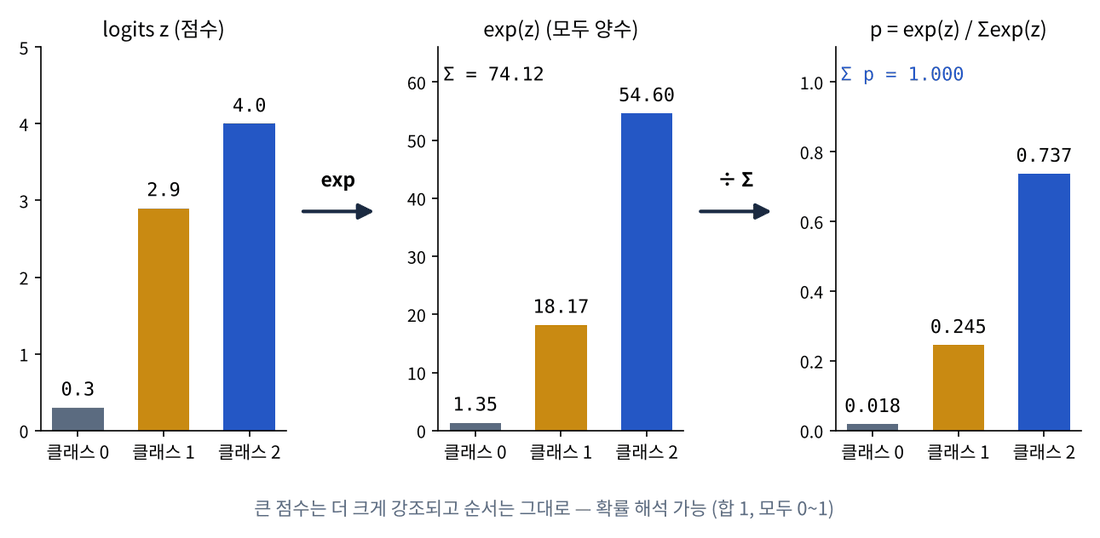

1. `exp` 로 모든 점수를 **양수**로 만들고, 큰 점수는 더 크게 벌립니다.
2. 전체 합으로 나눠 **합이 1** 이 되게 합니다 → 확률로 읽을 수 있음.
3. `exp` 는 증가 함수라 **순서는 그대로** — 가장 큰 점수가 가장 큰 확률. 그래서 추론에서 답만 필요하면 softmax 없이 `argmax(A)` 만 해도 됩니다.

Day 1 7교시에서 본 것처럼 `exp(1000)` 은 **overflow** 입니다. 실제로 확인해 봅니다.

In [ ]:
def softmax_naive(a):
    return np.exp(a) / np.sum(np.exp(a))

print(softmax_naive(np.array([0.3, 2.9, 4.0])))
with np.errstate(over="ignore", invalid="ignore"):
    print(softmax_naive(np.array([1010.0, 1000.0, 990.0])))      # → nan

**해결: 최댓값을 빼고 계산한다.** 분자 · 분모에 같은 수 $e^{-C}$ 를 곱하면 값이 변하지 않으므로

$$\frac{e^{a_k}}{\sum_i e^{a_i}} = \frac{e^{a_k - C}}{\sum_i e^{a_i - C}}, \qquad C = \max_i a_i$$

이렇게 하면 가장 큰 지수가 $e^0 = 1$ 이 되어 overflow 가 사라집니다.

**문제 6-1** 수치적으로 안정한 softmax 를 완성하세요. 배치 (N, 클래스) 입력에서도 **행마다** 동작해야 합니다 — Day 1 의 `axis` 와 `keepdims` 를 쓰세요 (`axis=-1` 은 마지막 축, 배치면 `axis=1` 과 같음).

In [ ]:
def softmax(A):
    A = A - ____
    expA = np.exp(A)
    return expA / ____

In [ ]:
assert np.allclose(softmax(np.array([0.3, 2.9, 4.0])), [0.01821127, 0.24519181, 0.73659691])
assert np.allclose(softmax(np.array([1010.0, 1000.0, 990.0])), [9.99954600e-01, 4.53978686e-05, 2.06106005e-09])
B = np.array([[1.0, 2.0, 3.0], [1000.0, 1000.0, 1000.0]])
assert softmax(B).shape == (2, 3) and np.allclose(softmax(B).sum(axis=1), 1)
assert np.argmax(softmax(B[0])) == np.argmax(B[0])
print("✅", softmax(np.array([1010.0, 1000.0, 990.0])))

In [ ]:
#@title 🔒 정답 보기 6-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTEg4pSA4pSACmRlZiBzb2Z0bWF4KEEpOgogICAgQSA9IEEgLSBBLm1heChheGlzPS0x"
    "LCBrZWVwZGltcz1UcnVlKQogICAgZXhwQSA9IG5wLmV4cChBKQogICAgcmV0dXJuIGV4cEEgLyBleHBBLnN1bShh"
    "eGlzPS0xLCBrZWVwZGltcz1UcnVlKQoK8J+SoSDtlbTshKQKa2VlcGRpbXM9VHJ1ZSDqsIAg7JeG7Jy866m0IEEu"
    "bWF4KGF4aXM9LTEpIOydtCAoTiwpIOydtCDrkJjslrQgKE4sIEMpIOyZgCDrkqQg7LaV7J20IOunnuyngCDslYrs"
    "lYQg67iM66Gc65Oc7LqQ7Iqk7YyFIOyYpOulmOqwgCDrgpjqsbDrgpgoTuKJoEMpLCBOPUMg7J28IOuVjOuKlCDs"
    "mKTrpZgg7JeG7J20IOyXieuase2VnCDstpXsnLzroZwg67m86rKMIOuQqeuLiOuLpC4gKE4sIDEpIOuhnCDrgqjq"
    "sqjslbwg7ZaJ66eI64ukIOyekOq4sCDstZzrjJPqsJLsnYQg67qN64uI64ukLg=="
).decode("utf-8"))

### One-hot 인코딩 — 정답을 확률 분포 모양으로

정답 레이블 `t = 2` (숫자 2) 를 출력과 같은 모양의 벡터로 바꿉니다. 정답 자리만 1, 나머지는 0 입니다.

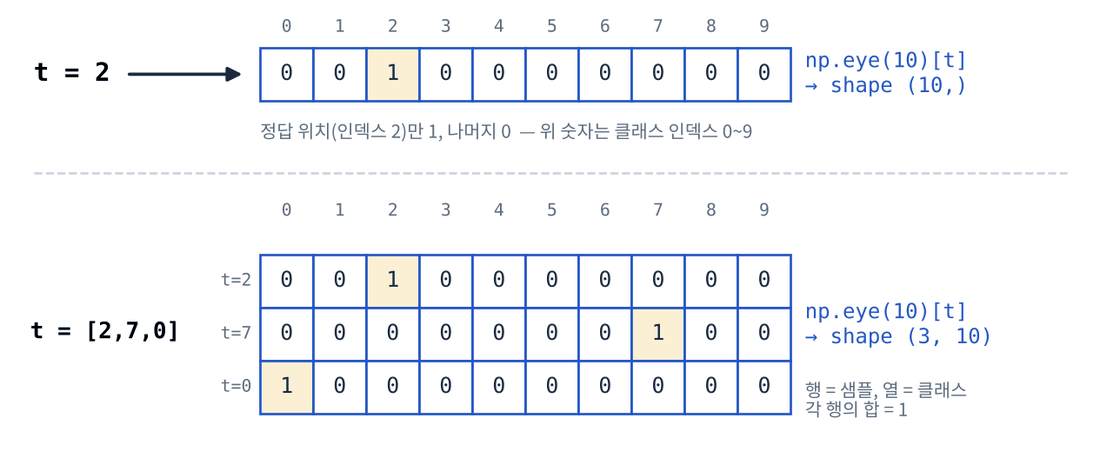

`np.eye(10)` 은 10×10 단위 행렬이고, 그 **t 번째 행**이 바로 one-hot 벡터입니다. 레이블 배열을 인덱스로 넣으면 배치 전체가 한 번에 바뀝니다 (Day 1 의 팬시 인덱싱).

**문제 6-2** 레이블(정수 또는 정수 배열)을 one-hot 으로 바꾸는 함수를 완성하세요.

In [ ]:
def one_hot(t, num_classes=10):
    return ____

In [ ]:
assert one_hot(2).tolist() == [0, 0, 1, 0, 0, 0, 0, 0, 0, 0]
assert one_hot(np.array([2, 7, 0])).shape == (3, 10) and one_hot(np.array([2, 7, 0]))[1, 7] == 1
print("✅\n", one_hot(np.array([2, 7, 0])))

In [ ]:
#@title 🔒 정답 보기 6-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTIg4pSA4pSACmRlZiBvbmVfaG90KHQsIG51bV9jbGFzc2VzPTEwKToKICAgIHJldHVy"
    "biBucC5leWUobnVtX2NsYXNzZXMpW3Rd"
).decode("utf-8"))

### 손실 함수 두 가지

$$\text{MSE} = \frac{1}{K}\sum_k (y_k - t_k)^2 \qquad\qquad \text{CE} = -\sum_k t_k \log y_k$$

one-hot 에서는 $t_k$ 가 정답 자리만 1 이므로 **CE = −log(정답 클래스의 확률)** 입니다. 정답 확률이 1 이면 손실 0, 0 에 가까울수록 손실이 무한히 커집니다 (Day 1 7교시의 −log p 그래프).

**문제 6-3 · 6-4** 두 손실 함수를 완성하세요. `log(0)` 을 피하려고 아주 작은 값 `1e-7` 을 더하고, 배치면 샘플 수 N 으로 나눠 **평균**을 냅니다.

In [ ]:
def mse(y, t):
    return ____

In [ ]:
#@title 🔒 정답 보기 6-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTMg4pSA4pSACmRlZiBtc2UoeSwgdCk6CiAgICByZXR1cm4gbnAubWVhbigoeSAtIHQp"
    "ICoqIDIp"
).decode("utf-8"))

In [ ]:
def cross_entropy(y, t):
    if y.ndim == 1:                          # 샘플 하나면 배치 하나로
        y, t = y.reshape(1, -1), t.reshape(1, -1)
    N = y.shape[0]
    return ____

In [ ]:
t_ex = one_hot(2)
y_good = np.array([0.1, 0.05, 0.6, 0.0, 0.05, 0.1, 0.0, 0.1, 0.0, 0.0])      # 정답(2)에 0.6
y_bad  = np.array([0.1, 0.05, 0.1, 0.0, 0.05, 0.1, 0.0, 0.6, 0.0, 0.0])      # 정답에 0.1, 7 에 0.6
print(f"좋은 예측: MSE {mse(y_good, t_ex):.4f}  CE {cross_entropy(y_good, t_ex):.4f}")
print(f"나쁜 예측: MSE {mse(y_bad, t_ex):.4f}  CE {cross_entropy(y_bad, t_ex):.4f}")
assert np.isclose(mse(y_good, t_ex), 0.0195) and np.isclose(cross_entropy(y_good, t_ex), 0.5108, atol=1e-4)
assert np.isclose(cross_entropy(y_bad, t_ex), 2.3026, atol=1e-4)
assert np.isclose(cross_entropy(np.vstack([y_good, y_bad]), np.vstack([t_ex, t_ex])), (0.5108 + 2.3026) / 2, atol=1e-4)
print("✅")

In [ ]:
#@title 🔒 정답 보기 6-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTQg4pSA4pSACmRlZiBjcm9zc19lbnRyb3B5KHksIHQpOgogICAgaWYgeS5uZGltID09"
    "IDE6ICAgICAgICAgICAgICAgICAgICAgICAgICAjIOyDmO2UjCDtlZjrgpjrqbQg67Cw7LmYIO2VmOuCmOuhnAog"
    "ICAgICAgIHksIHQgPSB5LnJlc2hhcGUoMSwgLTEpLCB0LnJlc2hhcGUoMSwgLTEpCiAgICBOID0geS5zaGFwZVsw"
    "XQogICAgcmV0dXJuIC1ucC5zdW0odCAqIG5wLmxvZyh5ICsgMWUtNykpIC8gTg=="
).decode("utf-8"))

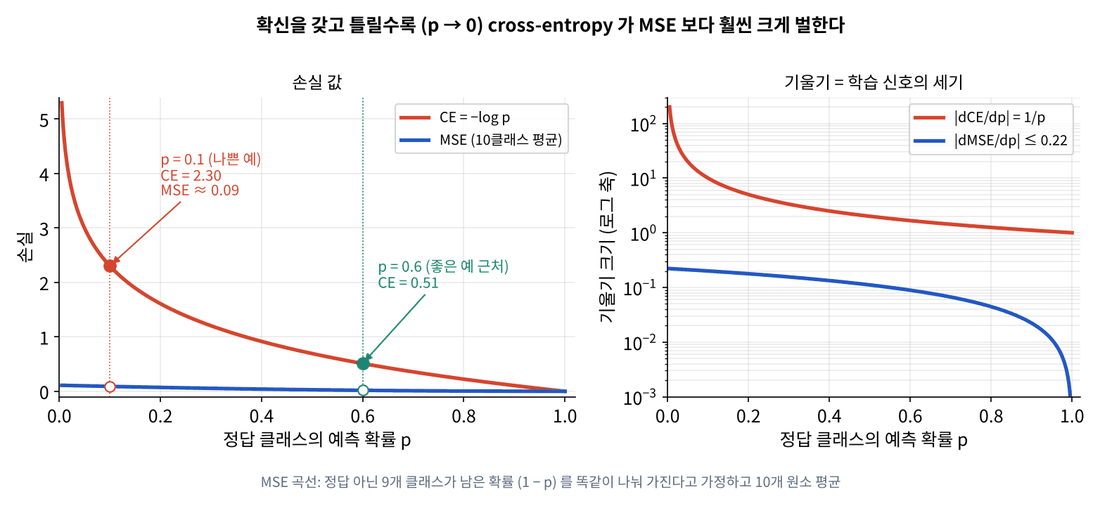

분류에 Cross-Entropy 를 쓰는 이유가 그래프에 보입니다. 정답 확률이 0.6 → 0.1 로 떨어지면 **MSE 는 조금** 늘지만 **CE 는 크게** 늘어납니다. "확신하며 틀린" 예측에 큰 벌점을 주므로 학습 신호가 강합니다. 또 softmax 와 CE 를 함께 쓰면 기울기가 `y − t` 라는 아주 간단한 식이 되는데, Day 3 역전파에서 직접 유도합니다.

#### ⚠️ 자주 하는 실수

- softmax 에 `keepdims` 를 빼먹음 → 배치에서 브로드캐스팅 오류 (또는 정사각일 때 조용히 틀림).
- `np.log(y)` 에 `1e-7` 을 빼먹음 → 확률 0 인 칸에서 `-inf`, 이후 모든 값이 `nan`.
- 레이블 `t` 를 one-hot 으로 바꾸지 않고 `t * np.log(y)` → 정수 2 가 모든 칸에 곱해져 엉뚱한 손실.
- 배치 손실을 N 으로 나누지 않음 → 배치 크기에 따라 손실 · 기울기 크기가 달라져 학습률을 맞추기 어려움.

#### 📌 6교시 정리

- 회귀 = identity + MSE, 이진 분류 = sigmoid + BCE, 다중 분류 = softmax + CE.
- softmax 는 **최댓값을 빼고** 계산 (`keepdims=True`), 순서는 바뀌지 않는다.
- one-hot = `np.eye(K)[t]`, CE = −log(정답 확률), `+ 1e-7`, 배치 평균.

## 7교시 — 선형 회귀를 경사하강으로

지금까지 모델(순전파)과 손실을 만들었습니다. 이제 Day 1 의 **경사하강**을 붙여 처음으로 **데이터에서 파라미터를 학습**합니다. 가장 단순한 모델, 출력 뉴런 하나짜리 회귀로 시작합니다. 가설은 5교시 층 하나와 똑같은 모양입니다.

$$Y = XW + b \qquad X: (N, 1),\quad W: (1, 1),\quad b: (1,),\quad Y: (N, 1)$$

입력이 특성 하나뿐이라 $W$ 가 1×1 이지만, 특성이 d 개면 $X: (N, d)$, $W: (d, 1)$ 로 **코드 한 글자 바꾸지 않고** 그대로 쓰입니다 (8교시에서 d = 2).

> 🎬 **애니메이션** [D2-8 선형 회귀 경사하강](https://imguru-mooc.github.io/AI_CAMPUS/NN-day2/animation.html#d2-8)  
> 📝 **워크시트** [7교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/NN-day2/worksheet.html#t7)  
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

In [ ]:
rng7 = np.random.default_rng(0)
X = rng7.uniform(0, 1, (50, 1))                        # 입력 50개, shape (50, 1) — 행 = 샘플
T = 2.0 * X + 1.0 + rng7.normal(0, 0.1, (50, 1))      # 정답: 진짜 규칙 2x + 1 + 잡음

print("X", X.shape, " T", T.shape)
plt.scatter(X, T, s=15); plt.xlabel("x"); plt.ylabel("t"); plt.title("training data (50)"); plt.grid(alpha=.3); plt.show()

### 기울기를 손으로 유도하기

손실은 MSE 에 **½** 을 붙여 씁니다. ½ 은 최솟값의 위치를 바꾸지 않고, 미분할 때 나오는 2 를 지워 식을 깔끔하게 만듭니다.

$$L(W, b) = \frac{1}{2N}\sum_{i} (y_i - t_i)^2, \qquad y_i = x_i W + b$$

샘플 하나의 손실 $\tfrac12 (y - t)^2$ 를 미분합니다. 바깥 $\tfrac12(\cdot)^2$ 의 미분 $(y - t)$ 에 안쪽 $y = xW + b$ 의 미분을 곱합니다 (연쇄 법칙 — Day 3 에서 본격적으로).

$$\frac{\partial}{\partial W}\,\tfrac12 (y - t)^2 = (y - t)\cdot\frac{\partial y}{\partial W} = (y - t)\,x, \qquad \frac{\partial}{\partial b}\,\tfrac12 (y - t)^2 = (y - t)$$

샘플 N 개는 평균을 냅니다. $(y_i - t_i)\,x_i$ 를 모두 더하는 일은 행렬곱 $X^\top (Y - T)$ 한 번입니다.

$$\frac{\partial L}{\partial W} = \frac{1}{N}\, X^\top (Y - T), \qquad \frac{\partial L}{\partial b} = \frac{1}{N}\sum_i (y_i - t_i)$$

| 식 | shape | 뜻 |
|---|---|---|
| $Y - T$ | (N, 1) | 샘플마다의 **오차** |
| $(y - t)\,x$ | — | 오차 × 입력 — 입력이 큰 샘플일수록 그 가중치의 책임이 크다 |
| $X^\top (Y - T)$ | (1, N) @ (N, 1) = (1, 1) | N 개의 $(y - t)x$ 를 한 번에 더한 것 — **$W$ 와 같은 shape** |

- 예측이 정답보다 **크면** $(y - t) > 0$ → 기울기 양수 → 경사하강 $W - \eta\cdot(\text{기울기})$ 가 $W$ 를 **줄인다**.
- 2교시 퍼셉트론 학습 규칙 $W \leftarrow W - \eta\,(y - t)\,x$ 와 **같은 모양**입니다. 퍼셉트론의 $y$ 는 0/1 계단 출력, 여기의 $y$ 는 연속값이라는 차이뿐입니다.

**문제 7-1** 유도한 식을 코드로 옮기세요. `X.T @ (Y - T)` 가 $\sum_i (y_i - t_i)x_i$, `len(X)` 가 N 입니다. 편향은 `axis=0` 으로 평균을 내 `b` 와 같은 shape (1,) 로 만듭니다.

In [ ]:
def grads(X, T, W, b):
    Y = X @ W + b                                # 가설 Y = XW + b
    dW = ____               # (1/N) Σ (y − t) x
    db = ____               # (1/N) Σ (y − t)
    return dW, db

In [ ]:
dW0, db0 = grads(X, T, np.zeros((1, 1)), np.zeros(1))
assert dW0.shape == (1, 1) and db0.shape == (1,)
assert np.isclose(db0[0], -np.mean(T)) and np.isclose(dW0[0, 0], -np.mean(X * T))
print("✅ W = b = 0 에서  dW =", dW0.ravel(), " db =", db0, " (오차가 모두 음수 → 둘 다 키우는 방향)")

In [ ]:
#@title 🔒 정답 보기 7-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTEg4pSA4pSACmRlZiBncmFkcyhYLCBULCBXLCBiKToKICAgIFkgPSBYIEAgVyArIGIg"
    "ICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICMg6rCA7ISkIFkgPSBYVyArIGIKICAgIGRXID0gWC5UIEAg"
    "KFkgLSBUKSAvIGxlbihYKSAgICAgICAgICAgICAgICMgKDEvTikgzqMgKHkg4oiSIHQpIHgKICAgIGRiID0gbnAu"
    "bWVhbihZIC0gVCwgYXhpcz0wKSAgICAgICAgICAgICAgICMgKDEvTikgzqMgKHkg4oiSIHQpCiAgICByZXR1cm4g"
    "ZFcsIGRi"
).decode("utf-8"))

**문제 7-2** 학습 루프를 완성하세요. `W`, `b` 를 0 에서 시작해 학습률 **1.0** 으로 200 epoch 갱신합니다.

½ 을 붙여 기울기가 MSE 기울기의 절반이 되었으므로, 학습률 1.0 은 "MSE 기울기에 학습률 0.5" 와 똑같은 걸음입니다.

In [ ]:
W = np.zeros((1, 1))
b = np.zeros(1)
lr = 1.0
loss_hist = []
for epoch in range(200):
    dW, db = grads(X, T, W, b)
    W = ____
    b = ____
    loss_hist.append(0.5 * np.mean((X @ W + b - T) ** 2))

In [ ]:
w_, b_ = W.item(), b.item()
print(f"학습 결과 W = {w_:.4f}, b = {b_:.4f}, L = {loss_hist[-1]:.4f}  (MSE = {2 * loss_hist[-1]:.4f})")
w_ls, b_ls = np.polyfit(X.ravel(), T.ravel(), 1)
print(f"최소제곱 해 W = {w_ls:.4f}, b = {b_ls:.4f}")
assert W.shape == (1, 1) and b.shape == (1,)
assert abs(w_ - w_ls) < 1e-3 and abs(b_ - b_ls) < 1e-3

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].scatter(X, T, s=15); xx = np.array([[0.0], [1.0]])
ax[0].plot(xx, xx @ W + b, "r", label=f"Y = X*{w_:.2f} + {b_:.2f}")
ax[0].plot(xx, 2 * xx + 1, "g--", label="true rule 2x + 1"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(loss_hist); ax[1].set_yscale("log"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("L = MSE / 2"); ax[1].grid(alpha=.3)
plt.show(); print("✅")

In [ ]:
#@title 🔒 정답 보기 7-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTIg4pSA4pSAClcgPSBucC56ZXJvcygoMSwgMSkpCmIgPSBucC56ZXJvcygxKQpsciA9"
    "IDEuMApsb3NzX2hpc3QgPSBbXQpmb3IgZXBvY2ggaW4gcmFuZ2UoMjAwKToKICAgIGRXLCBkYiA9IGdyYWRzKFgs"
    "IFQsIFcsIGIpCiAgICBXID0gVyAtIGxyICogZFcKICAgIGIgPSBiIC0gbHIgKiBkYgogICAgbG9zc19oaXN0LmFw"
    "cGVuZCgwLjUgKiBucC5tZWFuKChYIEAgVyArIGIgLSBUKSAqKiAyKSk="
).decode("utf-8"))

**문제 7-3** 방금 학습에 쓴 손 유도 기울기가 정말 맞았는지 Day 1 의 `numerical_gradient` 로 검증합니다. `W`, `b` 를 배열 하나 `params = [W, b]` 로 묶은 손실 함수를 만들면 그대로 쓸 수 있습니다.

In [ ]:
def loss_params(params):                 # params = [W, b]
    W_ = params[:1].reshape(1, 1)
    b_ = params[1:]
    return 0.5 * np.mean((X @ W_ + b_ - T) ** 2)

p0 = np.array([0.5, 0.5])
num_g = ____
dW_a, db_a = grads(X, T, np.array([[0.5]]), np.array([0.5]))
ana_g = np.r_[dW_a.ravel(), db_a]

In [ ]:
print("수치 미분:", num_g, "\n해석 미분:", ana_g)
assert np.allclose(num_g, ana_g, atol=1e-6); print("✅ 손으로 유도한 기울기 X.T @ (Y - T) / N 이 맞습니다")

In [ ]:
#@title 🔒 정답 보기 7-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTMg4pSA4pSACmRlZiBsb3NzX3BhcmFtcyhwYXJhbXMpOiAgICAgICAgICAgICAgICAg"
    "IyBwYXJhbXMgPSBbVywgYl0KICAgIFdfID0gcGFyYW1zWzoxXS5yZXNoYXBlKDEsIDEpCiAgICBiXyA9IHBhcmFt"
    "c1sxOl0KICAgIHJldHVybiAwLjUgKiBucC5tZWFuKChYIEAgV18gKyBiXyAtIFQpICoqIDIpCgpwMCA9IG5wLmFy"
    "cmF5KFswLjUsIDAuNV0pCm51bV9nID0gbnVtZXJpY2FsX2dyYWRpZW50KGxvc3NfcGFyYW1zLCBwMCkKZFdfYSwg"
    "ZGJfYSA9IGdyYWRzKFgsIFQsIG5wLmFycmF5KFtbMC41XV0pLCBucC5hcnJheShbMC41XSkpCmFuYV9nID0gbnAu"
    "cl9bZFdfYS5yYXZlbCgpLCBkYl9hXQoK8J+SoSDtlbTshKQK7J20IOu5hOq1kOqwgCBEYXkgMyDsl5DshJwg7Jet"
    "7KCE7YyMIOq1rO2YhOydhCDqsoDspp3tlaAg65WMIOyTsOuKlCBncmFkaWVudCBjaGVjayDsnZgg7LaV7IaM7YyQ"
    "7J6F64uI64ukLiDsiJjsuZgg66+467aE7J2AIO2MjOudvOuvuO2EsOuniOuLpCDshpDsi6TsnYQgMuuyiOyUqSDq"
    "s4TsgrDtlZjrr4DroZwg64qQ66as7KeA66eMIOygle2Zle2VtOyEnCAn7KCV64u17KeAJ+uhnCDslIHri4jri6Qu"
    "IMK9IOydhCDrubzqs6AgTVNFIOq3uOuMgOuhnCDrr7jrtoTtlojri6TrqbQg7ZW07ISdIOuvuOu2hOydgCAywrdY"
    "LlQgQCAoWSAtIFQpIC8gTiDsnbTslrTslbwg66ee7Iq164uI64ukLg=="
).decode("utf-8"))

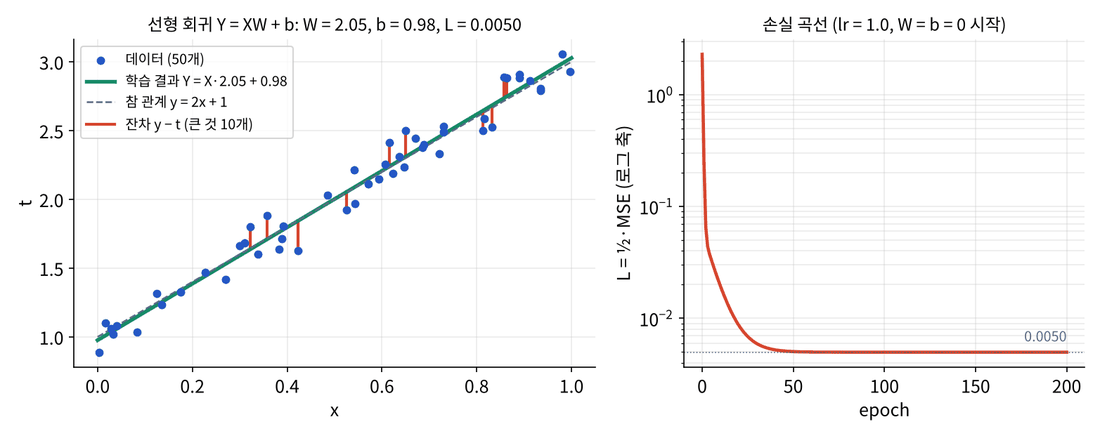

빨간 세로선은 **잔차(residual)** $y_i - t_i$ 입니다. 손실은 이 길이의 제곱 평균(의 절반)이고, 경사하강은 잔차들이 전체적으로 작아지는 방향으로 직선을 돌리고 옮깁니다. 오른쪽 손실 곡선(로그 축)은 처음 몇 epoch 에 크게 떨어지고 이후 바닥에 붙습니다.

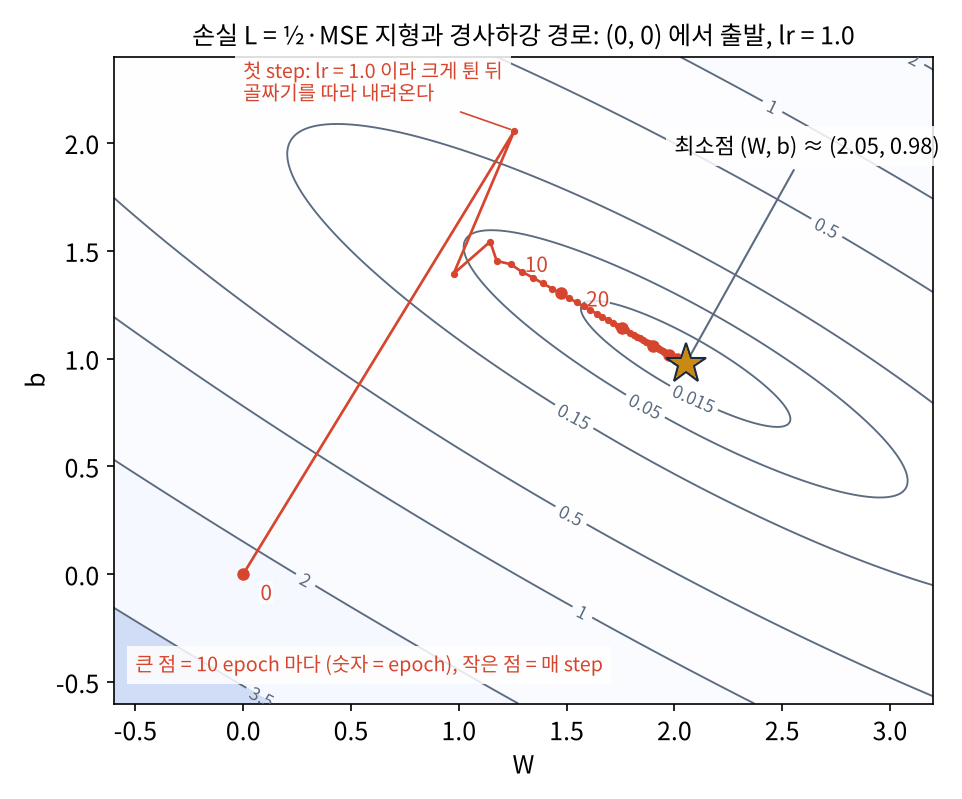

손실을 $(W, b)$ 평면 위의 지형으로 그리면 Day 1 8교시의 $x^2 + 3y^2$ 와 같은 **타원 골짜기**입니다. 경사하강은 (0, 0) 에서 출발해 골짜기 바닥(최소제곱 해)으로 내려갑니다. 잡음 때문에 바닥이 정확히 (2, 1) 은 아니고 (2.05, 0.98) 입니다 — 모델은 **데이터가 보여 준 만큼만** 배웁니다.

### 실험 — 학습률을 바꿔 보기

아래 셀에서 학습률 0.2 · 1.0 · 2.0 을 비교하세요. 이 데이터에서는 약 **1.54** 를 넘으면 발산합니다. Day 1 의 "가장 가파른 방향이 학습률 상한을 정한다"와 같은 현상입니다.

In [ ]:
for lr_try in [0.2, 1.0, 2.0]:
    W_, b_ = np.zeros((1, 1)), np.zeros(1)
    with np.errstate(over="ignore", invalid="ignore"):
        for _ in range(200):
            dW_, db_ = grads(X, T, W_, b_)
            W_, b_ = W_ - lr_try * dW_, b_ - lr_try * db_
    print(f"lr = {lr_try}:  W = {W_.item():12.4g}, b = {b_.item():12.4g}")

#### ⚠️ 자주 하는 실수

- `X` 를 `rng.uniform(0, 1, 50)` 처럼 1차원 (50,) 으로 만들면 `X.T` 가 그대로 (50,) 이고 `X @ W` 도 shape 이 어긋납니다. **행 = 샘플, 열 = 특성** — (N, 1) 로 만드세요.
- `/ len(X)` 를 빼먹으면 기울기가 데이터 수(50)배 커져 바로 발산합니다.
- `np.mean(Y - T)` 처럼 `axis` 없이 쓰면 스칼라가 됩니다. 동작은 하지만 `b` 의 shape (1,) 와 맞추려면 `axis=0`.
- `W` 를 갱신한 뒤 **새 W 로 db 를 다시 계산** — 두 기울기는 같은 시점의 (W, b) 에서 구해야 합니다. 그래서 `grads` 로 한 번에 구합니다.
- 손실이 줄지 않고 `nan` 이 되면 학습률이 너무 큰 것입니다 (발산).

#### 📌 7교시 정리

- 학습 = 순전파 $Y = XW + b$ → 손실 → 기울기 → 갱신, 이 고리를 epoch 만큼 반복.
- $L = \tfrac{1}{2N}\sum (y - t)^2$ 의 기울기: $\partial L/\partial W = X^\top (Y - T)/N$, $\partial L/\partial b = \text{mean}(Y - T)$ — 샘플 하나로 보면 **$(y - t)\,x$** 와 **$(y - t)$**.
- 손으로 유도한 기울기는 **수치 미분으로 검증**한다 (gradient check).
- 학습률이 너무 크면 발산, 작으면 느림.

## 8교시 — 미니 프로젝트: 로지스틱 회귀 분류기

오늘 배운 모든 것을 한 모델에 담습니다. 두 종류의 점(클래스 0, 1)을 나누는 **이진 분류기**를 만들고 경사하강으로 학습합니다. 이름은 "회귀"지만 **분류** 모델입니다 — 가설 $XW + b$ 에 sigmoid 를 씌운 것, 즉 1교시 퍼셉트론의 "미분 가능한 버전"입니다.

$$P = \sigma(XW + b) = P(\text{클래스 } 1 \mid x) \qquad X: (N, 2),\quad W: (2, 1),\quad b: (1,),\quad P: (N, 1)$$

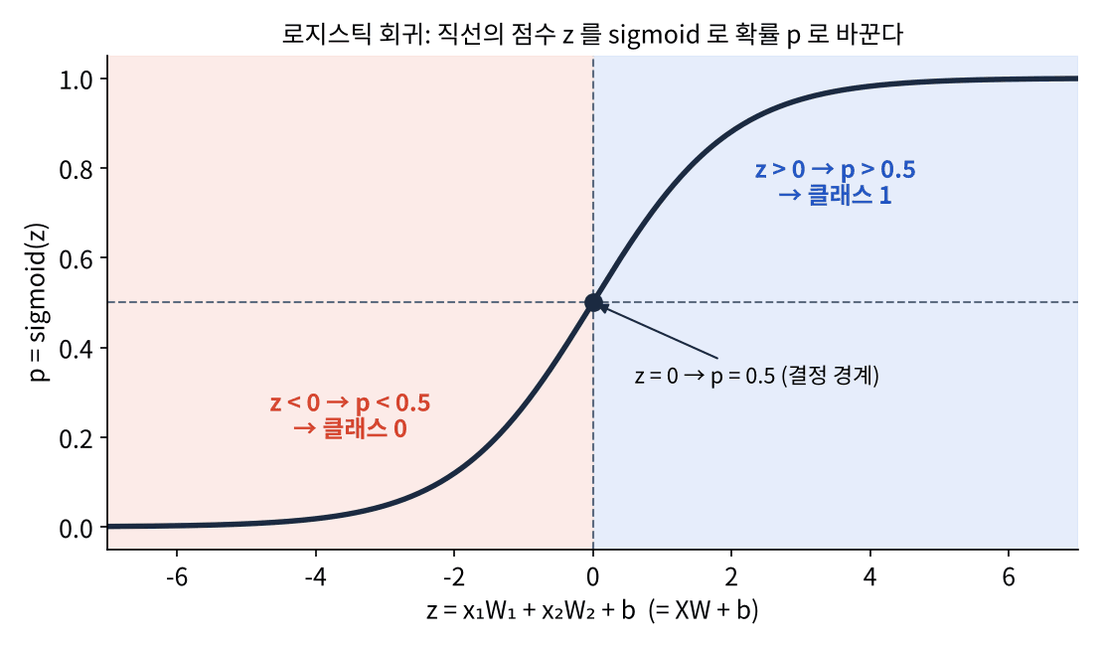

이진 분류의 손실은 **이진 교차 엔트로피 (BCE)** 입니다. 6교시 CE 를 클래스 두 개로 쓴 것입니다.

$$L = \text{BCE} = -\frac{1}{N}\sum_i \big[\, t_i \log p_i + (1 - t_i)\log(1 - p_i) \,\big]$$

정답이 1 이면 $-\log p$, 정답이 0 이면 $-\log(1 - p)$ 만 남습니다.

### 기울기 — 7교시와 똑같은 $(y - t)\,x$

샘플 하나로 연쇄 법칙을 적용하면 ($z = xW + b$, $p = \sigma(z)$)

$$\frac{\partial L}{\partial p} = \frac{p - t}{p(1 - p)}, \qquad \frac{\partial p}{\partial z} = p(1 - p) \;\;(\text{4교시 sigmoid}') \qquad\Rightarrow\qquad \frac{\partial L}{\partial z} = p - t$$

sigmoid 의 기울기 $p(1-p)$ 가 BCE 의 분모와 **깔끔하게 상쇄**됩니다. 나머지는 7교시와 같아서

$$\frac{\partial L}{\partial W} = \frac{1}{N}\, X^\top (P - T), \qquad \frac{\partial L}{\partial b} = \frac{1}{N}\sum_i (p_i - t_i)$$

**선형 회귀 (½MSE) 와 로지스틱 회귀 (sigmoid + BCE) 의 기울기가 같은 모양 — (예측 − 정답) × 입력** 입니다. 6교시에서 예고한 "softmax + CE 의 기울기 y − t" 도 같은 이야기이고, Day 3 역전파에서 다시 만납니다.

| 과제 | 내용 | 배점 |
|---|---|---|
| 1 | `predict_proba(X, W, b)` — 확률 계산 | 20 |
| 2 | `bce_loss(P, T)` — 이진 교차 엔트로피 | 20 |
| 3 | `gradients(X, T, W, b)` + 학습 루프 (정확도 ≥ 0.9) | 30 |
| 4 | 결정 경계 그리기 | 20 |
| 5 | 결과 해석 (마크다운 답변) | 10 |

과제 끝의 **채점 셀**을 실행하면 자동 채점 점수가 나옵니다(과제 5 는 강사 채점).

> 🎬 **애니메이션** [D2-9 로지스틱 회귀 결정 경계](https://imguru-mooc.github.io/AI_CAMPUS/NN-day2/animation.html#d2-9)  
> 📝 **워크시트** [8교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/NN-day2/worksheet.html#t8)  
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

In [ ]:
# 데이터 — 이 셀은 그대로 실행하세요 (8교시에서는 X, T 를 분류 데이터로 새로 정의합니다)
rng8 = np.random.default_rng(1)
X0 = rng8.normal([-1, -1], 0.8, (100, 2))        # 클래스 0: (-1, -1) 근처
X1 = rng8.normal([1, 1], 0.8, (100, 2))          # 클래스 1: (1, 1) 근처
X = np.vstack([X0, X1])                          # (200, 2)
T = np.array([0] * 100 + [1] * 100).reshape(-1, 1)   # (200, 1)

plt.scatter(X0[:, 0], X0[:, 1], s=15, label="class 0"); plt.scatter(X1[:, 0], X1[:, 1], s=15, label="class 1")
plt.legend(); plt.axis("equal"); plt.grid(alpha=.3); plt.title("classification data (200)"); plt.show()
print("X", X.shape, " T", T.shape)

### 과제 1 — `predict_proba` (20점)

가설 $XW + b$ 에 sigmoid 를 씌워 모든 샘플의 클래스 1 확률을 계산합니다. `W` 는 (2, 1), `b` 는 (1,) 이고 결과는 (200, 1) 입니다.

In [ ]:
def predict_proba(X, W, b):
    Z = ____          # (200, 1)
    return ____

In [ ]:
#@title 🔒 정답 보기 8-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTEg4pSA4pSACmRlZiBwcmVkaWN0X3Byb2JhKFgsIFcsIGIpOgogICAgWiA9IFggQCBX"
    "ICsgYiAgICAgICAgICAjICgyMDAsIDEpCiAgICByZXR1cm4gc2lnbW9pZChaKQ=="
).decode("utf-8"))

### 과제 2 — `bce_loss` (20점)

확률 `P` 와 정답 `T` (둘 다 (200, 1)) 로 BCE 를 계산합니다. `log(0)` 을 피하려고 `1e-7` 을 더하세요.

In [ ]:
def bce_loss(P, T):
    return ____

In [ ]:
P_init = predict_proba(X, np.zeros((2, 1)), np.zeros(1))
print("학습 전 (W = 0, b = 0) 손실:", bce_loss(P_init, T), " ← 모든 확률 0.5 일 때 log 2 =", np.log(2))

In [ ]:
#@title 🔒 정답 보기 8-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTIg4pSA4pSACmRlZiBiY2VfbG9zcyhQLCBUKToKICAgIHJldHVybiAtbnAubWVhbihU"
    "ICogbnAubG9nKFAgKyAxZS03KSArICgxIC0gVCkgKiBucC5sb2coMSAtIFAgKyAxZS03KSk="
).decode("utf-8"))

### 과제 3 — 기울기와 학습 루프 (30점)

**(1)** 위에서 유도한 기울기 $\frac{1}{N}X^\top (P - T)$, $\text{mean}(P - T)$ 를 `gradients` 로 구현하세요. 7교시 `grads` 와 `Y` 가 `P` 로 바뀐 것 말고는 같습니다.

In [ ]:
def gradients(X, T, W, b):
    P = predict_proba(X, W, b)
    dW = ____        # (2, 1) — W 와 같은 shape
    db = ____        # (1,)
    return dW, db

In [ ]:
#@title 🔒 정답 보기 8-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTMg4pSA4pSACmRlZiBncmFkaWVudHMoWCwgVCwgVywgYik6CiAgICBQID0gcHJlZGlj"
    "dF9wcm9iYShYLCBXLCBiKQogICAgZFcgPSBYLlQgQCAoUCAtIFQpIC8gbGVuKFgpICAgICAgICAjICgyLCAxKSDi"
    "gJQgVyDsmYAg6rCZ7J2AIHNoYXBlCiAgICBkYiA9IG5wLm1lYW4oUCAtIFQsIGF4aXM9MCkgICAgICAgICMgKDEs"
    "KQogICAgcmV0dXJuIGRXLCBkYg=="
).decode("utf-8"))

**(2)** 손 유도 기울기가 맞는지 `numerical_gradient` 로 확인합니다 — 이 셀은 그대로 실행하세요.

In [ ]:
W_chk, b_chk = np.array([[0.3], [-0.2]]), np.array([0.1])
num_dW = numerical_gradient(lambda W_: bce_loss(predict_proba(X, W_, b_chk), T), W_chk.copy())
num_db = numerical_gradient(lambda b_: bce_loss(predict_proba(X, W_chk, b_), T), b_chk.copy())
ana_dW, ana_db = gradients(X, T, W_chk, b_chk)
print("dW  수치:", num_dW.ravel(), " 해석:", ana_dW.ravel())
print("db  수치:", num_db, "            해석:", ana_db)
print("일치" if np.allclose(num_dW, ana_dW, atol=1e-6) and np.allclose(num_db, ana_db, atol=1e-6) else "불일치 — gradients 를 다시 보세요")

**(3)** `W`, `b` 를 0 에서 시작해 학습률 0.5 로 300 번 갱신합니다. 마지막에 정확도(확률 > 0.5 를 클래스 1 로 예측했을 때 맞힌 비율)를 계산하세요.

In [ ]:
W = np.zeros((2, 1))
b = np.zeros(1)
lr = 0.5
loss_hist = []
for step in range(300):
    dW, db = ____
    W = ____
    b = ____
    loss_hist.append(bce_loss(predict_proba(X, W, b), T))

acc = ____
print("W =", W.ravel(), " b =", b, " 손실 =", round(loss_hist[-1], 4), " 정확도 =", acc)
plt.plot(loss_hist); plt.xlabel("step"); plt.ylabel("BCE"); plt.grid(alpha=.3); plt.show()

In [ ]:
#@title 🔒 정답 보기 8-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTQg4pSA4pSAClcgPSBucC56ZXJvcygoMiwgMSkpCmIgPSBucC56ZXJvcygxKQpsciA9"
    "IDAuNQpsb3NzX2hpc3QgPSBbXQpmb3Igc3RlcCBpbiByYW5nZSgzMDApOgogICAgZFcsIGRiID0gZ3JhZGllbnRz"
    "KFgsIFQsIFcsIGIpCiAgICBXID0gVyAtIGxyICogZFcKICAgIGIgPSBiIC0gbHIgKiBkYgogICAgbG9zc19oaXN0"
    "LmFwcGVuZChiY2VfbG9zcyhwcmVkaWN0X3Byb2JhKFgsIFcsIGIpLCBUKSkKCmFjYyA9IG5wLm1lYW4oKHByZWRp"
    "Y3RfcHJvYmEoWCwgVywgYikgPiAwLjUpID09IFQpCnByaW50KCJXID0iLCBXLnJhdmVsKCksICIgYiA9IiwgYiwg"
    "IiDshpDsi6QgPSIsIHJvdW5kKGxvc3NfaGlzdFstMV0sIDQpLCAiIOygle2ZleuPhCA9IiwgYWNjKQpwbHQucGxv"
    "dChsb3NzX2hpc3QpOyBwbHQueGxhYmVsKCJzdGVwIik7IHBsdC55bGFiZWwoIkJDRSIpOyBwbHQuZ3JpZChhbHBo"
    "YT0uMyk7IHBsdC5zaG93KCk="
).decode("utf-8"))

### 과제 4 — 결정 경계 (20점)

$p = 0.5$ 인 곳은 $z = 0$, 즉 $x_1 W_1 + x_2 W_2 + b = 0$ 인 **직선**입니다 (2교시 `boundary_x2` 와 같은 식). `W[0, 0]`, `W[1, 0]`, `b[0]` 으로 `x1s` 에 대한 `x2s` 를 계산해 데이터 위에 그리세요.

In [ ]:
x1s = np.linspace(-4, 4, 100)
x2s = ____

plt.scatter(X0[:, 0], X0[:, 1], s=15, label="class 0"); plt.scatter(X1[:, 0], X1[:, 1], s=15, label="class 1")
plt.plot(x1s, x2s, "k--", lw=2, label="decision boundary p = 0.5")
plt.xlim(-4, 4); plt.ylim(-4, 4); plt.legend(); plt.grid(alpha=.3); plt.title(f"logistic regression - accuracy {acc:.3f}"); plt.show()

In [ ]:
#@title 🔒 정답 보기 8-5 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTUg4pSA4pSACngxcyA9IG5wLmxpbnNwYWNlKC00LCA0LCAxMDApCngycyA9IC0oV1sw"
    "LCAwXSAqIHgxcyArIGJbMF0pIC8gV1sxLCAwXQoKcGx0LnNjYXR0ZXIoWDBbOiwgMF0sIFgwWzosIDFdLCBzPTE1"
    "LCBsYWJlbD0iY2xhc3MgMCIpOyBwbHQuc2NhdHRlcihYMVs6LCAwXSwgWDFbOiwgMV0sIHM9MTUsIGxhYmVsPSJj"
    "bGFzcyAxIikKcGx0LnBsb3QoeDFzLCB4MnMsICJrLS0iLCBsdz0yLCBsYWJlbD0iZGVjaXNpb24gYm91bmRhcnkg"
    "cCA9IDAuNSIpCnBsdC54bGltKC00LCA0KTsgcGx0LnlsaW0oLTQsIDQpOyBwbHQubGVnZW5kKCk7IHBsdC5ncmlk"
    "KGFscGhhPS4zKTsgcGx0LnRpdGxlKGYibG9naXN0aWMgcmVncmVzc2lvbiAtIGFjY3VyYWN5IHthY2M6LjNmfSIp"
    "OyBwbHQuc2hvdygp"
).decode("utf-8"))

### 과제 5 — 결과 해석 (10점)

아래 셀에 답을 쓰세요.

1. 결정 경계(확률 0.5 인 곳)가 **직선**이 되는 이유는? (힌트: sigmoid(0) = ?)
2. 학습을 300 step 보다 오래 계속하면 `W` 의 크기는 어떻게 될까? 손실과 확률에는 어떤 일이 생기나?
3. 1교시 퍼셉트론(계단 함수)에는 왜 이 경사하강 방법을 쓸 수 없나? (힌트: 계단 함수의 기울기)

✍️ *여기에 답을 쓰세요.*

In [ ]:
#@title 🔒 해설 보기 8교시 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIO2VtOyEpCDilIDilIAKMS4gc2lnbW9pZCh6KSA9IDAuNSDih5QgeiA9IDAg7J206rOgLCB6ID0geDHC"
    "t1cxICsgeDLCt1cyICsgYiAoPSB4VyArIGIpIOuKlCB4IOyXkCDrjIDtlZwgMeywqOyLneydtOuvgOuhnCB6ID0g"
    "MCDsnbgg7KCQ65Ok7J2YIOuqqOyehOydgCDsp4HshKDsnoXri4jri6QuIOuhnOyngOyKpO2LsSDtmozqt4DripQg"
    "7Y287IWJ7Yq466Gg7LKY65+8ICfsp4HshKAg7ZWY64KYJ+ydmCDrtoTrpZjquLDsnbTqs6AsIOqzoeyEoCDqsr3q"
    "s4TqsIAg7ZWE7JqU7ZWY66m0IOydgOuLiey4teydhCDsjJPslYTslbwg7ZWp64uI64ukKDPqtZDsi5wpLgoyLiDr"
    "jbDsnbTthLDqsIAg6rGw7J2YIOu2hOumrCDqsIDriqXtlZjrqbQgVyDrpbwg7YKk7Jq47IiY66GdIO2ZleuloOyd"
    "tCAwIOuYkOuKlCAxIOuhnCDrjZQg6rCA6rmM7JuM7KC4IOyGkOyLpOydtCDqs4Tsho0g7KGw6riI7JSpIOykhOyW"
    "tOuTreuLiOuLpC4g6re4656Y7IScIFcg7YGs6riw6rCAIOuBneyXhuydtCDsu6Tsp4DripQg6rK97Zal7J20IOye"
    "iOqzoCwg64SI66y0IO2ZleyLoO2VmOuKlCDrqqjrjbjsnYAg7IOIIOuNsOydtO2EsOyXkCDslb3tlbTsp4gg7IiY"
    "IOyeiOyKteuLiOuLpCjqs7zsoIHtlakpIOKAlCBEYXkgNCDsnZggd2VpZ2h0IGRlY2F5IOuhnCDrp4nsirXri4jr"
    "i6QuCjMuIOqzhOuLqCDtlajsiJjripQg6rGw7J2YIOuqqOuToCDqs7Psl5DshJwg6riw7Jq46riw6rCAIDAg7J20"
    "6528IFcg66W8IOyhsOq4iCDrsJTqv5Trj4Qg7IaQ7Iuk7J20IOuzgO2VmOyngCDslYrsirXri4jri6QuIOq4sOya"
    "uOq4sCAocCDiiJIgdCl4IOulvCDrp4zrk6Ag7Jew7IeEIOuyley5meydmCDqsIDsmrTrjbAg6rOg66asIOKIgnAv"
    "4oiCeiA9IHAoMSDiiJIgcCkg7J6Q66as7JeQIDAg7J20IOuTpOyWtOqwgCDquLDsmrjquLAg7KCE7LK06rCAIDAg"
    "7J20IOuQqeuLiOuLpC4g6rK97IKs7ZWY6rCV7J2AICLslrTripAg67Cp7Zal7Jy866GcIOuwlOq/lOyVvCDshpDs"
    "i6TsnbQg7KSE7Ja065Oc64qU7KeAIuqwgCDtlYTsmpTtlZjrr4DroZwg66ek64GE65+s7Jq0IHNpZ21vaWQg6rCA"
    "IO2VhOyalO2VqeuLiOuLpC4="
).decode("utf-8"))

### 채점 셀

In [ ]:
score = 0
try:
    Wt, bt = np.array([[1.0], [-2.0]]), np.array([0.5])
    assert predict_proba(X, Wt, bt).shape == (200, 1)
    assert np.allclose(predict_proba(X, Wt, bt), 1 / (1 + np.exp(-(X @ Wt + bt))))
    assert np.allclose(predict_proba(X, np.zeros((2, 1)), np.zeros(1)), 0.5)
    score += 20; print("✅ 과제 1  +20")
except Exception as e: print("❌ 과제 1", e)
try:
    P_half = np.full((200, 1), 0.5)
    assert np.isclose(bce_loss(P_half, T), np.log(2), atol=1e-5)
    assert bce_loss(predict_proba(X, np.array([[3.0], [3.0]]), np.zeros(1)), T) < bce_loss(P_half, T)
    score += 20; print("✅ 과제 2  +20")
except Exception as e: print("❌ 과제 2", e)
try:
    dW_c, db_c = gradients(X, T, np.zeros((2, 1)), np.zeros(1))
    assert dW_c.shape == (2, 1) and db_c.shape == (1,)
    assert np.allclose(dW_c, X.T @ (0.5 - T) / 200) and np.allclose(db_c, np.mean(0.5 - T))
    assert len(loss_hist) == 300 and loss_hist[-1] < loss_hist[0] and acc >= 0.9
    score += 30; print("✅ 과제 3  +30")
except Exception as e: print("❌ 과제 3", e)
try:
    assert x2s.shape == (100,)
    on_line = W[0, 0] * x1s + W[1, 0] * x2s + b[0]
    assert np.allclose(on_line, 0, atol=1e-6)
    score += 20; print("✅ 과제 4  +20")
except Exception as e: print("❌ 과제 4", e)
print(f"\n자동 채점 {score} / 90  (과제 5 는 강사 채점 10점)")

### 🔎 더 알아보기 — 학습된 분류기가 보는 세상

과제를 제출한 뒤에 보세요.

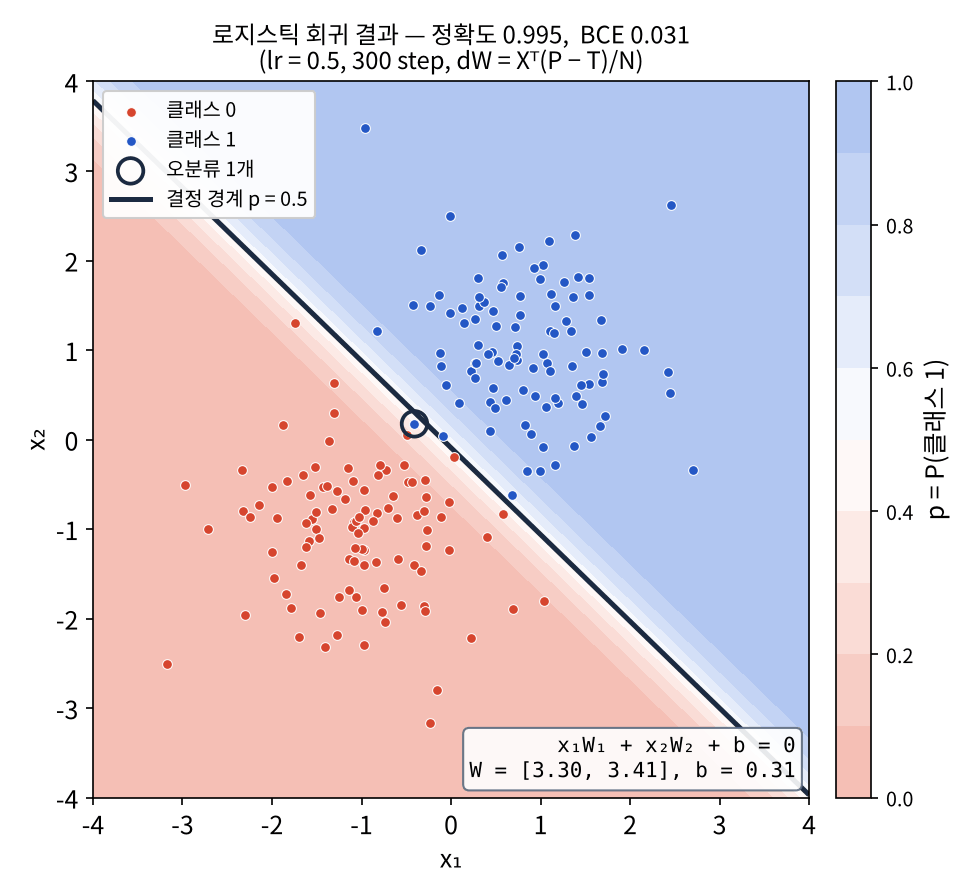

배경색은 모델이 각 위치에 매긴 **클래스 1 확률**입니다. 경계에서 멀어질수록 확신이 커지고(진한 색), 경계 근처의 점들은 확률이 0.5 에 가깝습니다 — 틀린 점 하나도 바로 이 근처에 있습니다.

### 왜 Day 3 에서 역전파가 필요한가

오늘은 모델이 층 하나라서 기울기 $(y - t)\,x$ 를 **손으로 유도**할 수 있었습니다. 5교시의 2-3-2-2 망이나 MNIST 784-100-10 처럼 층이 쌓이면 앞쪽 `W1` 의 기울기는 뒤쪽 층을 모두 거쳐 오는 긴 식이 되어 손으로 쓰기 어렵습니다. 그렇다고 수치 미분을 쓰면 파라미터마다 손실을 2번 계산해야 하므로, MNIST 망(파라미터 **79,510개**)은 step 한 번에 손실을 **159,020번** 계산해야 합니다.

Day 3 의 **역전파(backpropagation)** 는 오늘 본 "출력층의 오차 $(y - t)$" 를 층마다 거꾸로 전달하며 각 층의 $X^\top(\text{오차})$ 를 구하는 방법입니다. 순전파 한 번 + 역방향 한 번으로 모든 기울기를 한꺼번에 얻습니다.

In [ ]:
for n_params, name in [(3, "로지스틱 회귀"), (23, "5교시 2-3-2-2 망"), (79_510, "MNIST 784-100-10")]:
    print(f"{name:18s} 파라미터 {n_params:>7,}개 → step 당 손실 계산 {2 * n_params:>9,}번 (수치 미분)  vs  역전파 ≈ 2번")

## 오늘의 정리

### 셀프 체크

- [ ] 퍼셉트론의 가중치 · 편향이 결정 직선의 방향 · 위치를 정한다는 것을 설명할 수 있다
- [ ] 학습 규칙 $W \leftarrow W - \eta(y - t)x$ 가 틀렸을 때만 고친다는 것을 설명할 수 있다
- [ ] XOR 이 퍼셉트론 하나로 안 되고, 은닉층을 쌓으면 되는 이유를 말할 수 있다
- [ ] 활성화 함수가 비선형이어야 하는 이유와 sigmoid 의 기울기 소실을 설명할 수 있다
- [ ] 2-3-2-2 망의 순전파를 행렬로 쓰고, 각 층의 shape 와 파라미터 수를 셀 수 있다
- [ ] softmax 의 최댓값 빼기, one-hot, MSE · CE 를 구현할 수 있다
- [ ] 가설 $Y = XW + b$ 와 ½MSE 의 기울기 $X^\top(Y - T)/N$ 을 유도하고 수치 미분으로 검증할 수 있다
- [ ] 로지스틱 회귀를 기울기 $X^\top(P - T)/N$ 으로 학습시키고 결정 경계를 그릴 수 있다

### 내일 (Day 3) 예고

계산 그래프 → 연쇄 법칙 → 덧셈 · 곱셈 노드 → ReLU · Sigmoid · Affine · Softmax-with-Loss 계층의 **역전파** → gradient check → 미니배치 SGD → **MNIST 784-100-10 학습 (정확도 95% 이상)**. 오늘 만든 `sigmoid · relu · softmax · cross_entropy · forward` 와 Day 1 의 `numerical_gradient` 가 모두 계층 클래스로 다시 태어납니다.